# Similarity methods: facet weighting (method 1) and a FAME-inspired gate (method 2)

**What this notebook asks.** Step 4 combines the facets into one similarity score by giving every facet the same weight. This notebook tests two ways to weight them, and replaces the z ≥ 2 shortlist with mutual top 10:

- **Method 1, the updated baseline.** Each facet's score blends the embedding cosine with a TF-IDF word-overlap score, so boilerplate shared by most firms ("B2B:", "direct sales:") counts for little. Each facet is weighted by how much information both companies' texts carry on it, with a BM25-style saturation curve so a long facet can't dominate.
- **Method 2, after FAME** (Liu et al., [arXiv 2411.01457](https://arxiv.org/html/2411.01457v1)). Facets act as FAME's heads, and each one scores the pool on its own. A gate sets each target's facet weights by a fixed rule (information × sharpness). Facets written as `;` lists are matched piece by piece, the counterpart of FAME's experts within a head. Nothing is trained.

**Decisions this notebook applies (team, 2026-11-03).**
- Company size (F9) is out: it is too generic and hurt the comps.
- "Not applicable" ("none") counts as missing, so two "none"s no longer match at 1.00.
- Comps are the mutual top 10: each company is among the other's 10 most similar. A target with fewer than 3 mutual comps is topped up from its own top 10.
- The reviewers' scores are used under a fixed rule (section 4). Sol's grades are an alternative check that no decision rests on (section 5).

**What it does not do.** It makes no API calls and fits nothing, and it reads EV/EBITDA only in section 6, after every comp list is fixed. It reuses the saved embeddings, facets, split, reviewer labels, Sol grades and saved LLM-route outputs. It doesn't change `candidates.py` or the main `comps_and_valuation.ipynb`.

**Adding a facet.** The facet list is `facets.py`'s facets minus `facet_weighting.EXCLUDED_FACETS`. A new facet is picked up once it is filled, and only its new texts are embedded (the cache is keyed by text).

Code: `v1/scripts/facet_weighting.py` (methods) and `v1/scripts/similarity_eval.py` (evaluation), with tests. Outputs: `outputs-local/v1/similarity_methods/<run>/`.

## Results in brief (373 training targets; saved run in `outputs-local/v1/similarity_methods/`)

1. **On the reviewed comps, methods 1 and 2 find what v0 missed and drop what v0 wrongly listed** (majority grades, PCTY and WEN; section 4):
   - **Direct comps:** every method finds all of them. PCTY's ASUR, PAYC and ADP rank 1–3, and WEN's TXRH ranks 1–2.
   - **Adjacent comps:** methods 1 and 2 find all of them (PCTY 7/7 good, WEN 4/4). v0 misses BBSI for PCTY (rank 17) and BDL for WEN (rank 12). Both rise once "none" counts as missing.
   - **Non-comps:** v0 lists 3 of PCTY's 5 and 7 of WEN's 16 (packaged-food and beverage makers). Method 1 lists none; method 2 lists one (Lamb Weston). Most are removed by the mutual filter, not by the similarity.
   - **Precision@10:** WEN rises from 0.30 to 1.0 and PCTY from 0.67 to 1.0 (method 1).
   - **Robustness:** Barbara's and Matthew's own grades give the same picture. Riya's don't separate the methods: she counts the food makers as adjacent to WEN.
   - **Sol (alternative, 156 holdout targets):** the new lists keep 81–82% of each target's Sol-direct comps (v0: 84%) with a third as many Sol non-comps (1.0 per target against 3.0).
   - **Where the gain comes from:** the "none" fix (B1) and the mutual filter. The TF-IDF weights and blend (B2, B3) add no measurable gain on these comps. The blend has one visible side effect: Lamb Weston, a fries supplier, rises on shared words.
2. **Valuation does not move.** Median APE is 28.8% for v0's cosine top 10, 30.0% for method 1 and 30.3% for method 2. Every interval for the difference includes 0. With v0's one-way top 10 instead of the mutual filter, method 1 and method 2 give 29.7% and 30.2%, so it isn't the shorter lists. Comps that reviewers and Sol rate as better peers don't give closer EV/EBITDA estimates on this data, which matches v0's finding that the right peers still miss by about 30%.
3. **Which facets matter (method 2, section 4).** For WEN, revenue model does most of the separating: 0.050 of the 0.171 gap between good comps and non-comps. It also gets WEN's largest gate (14.0%), raised there by sharpness. For PCTY, whose non-comps are other software firms, the separation is spread across facets, and the gate's top facet (offering description) is not the best separator.
4. **Method 2 behaves like method 1.** Sharpness is about the same on every facet (2.8–3.5 SD), so the gate mostly follows the information score and differs little between targets. Without training data, the FAME adaptation adds little.
5. **Mutual top 10 stays small.** Method 1 lists a median of 7 comps and never more than 10. 11% of targets need the top-up to 3, and 1.3% have no mutual comp at all.

Two targets is too few to separate the methods on human labels. The sheet in section 8 has 2 new pairs for the reviewers, and adding targets to the golden set is the next step.

## 0. Inputs

In [1]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
sys.path.insert(0, str(ROOT / "v1" / "scripts"))
import facets as fc                     # also puts website_scrape/ and src/ on the path
import candidates as cd
import facet_weighting as fw
import similarity_eval as se
import golden_set as gs
import valuation as vl
from fill_facets import DEFAULT_OUT as FACETS_OUT, output_paths
from project_data import OUTPUTS_LOCAL

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 220)

RUN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
V1 = OUTPUTS_LOCAL / "v1"
OUT = V1 / "similarity_methods" / RUN
OUT.mkdir(parents=True, exist_ok=True)

# the SIC2 split every v0/v1 result since 2026-10-27 uses, and the universe it was made from
SPLIT_RUN = V1 / "split" / "20261027T204930Z"
split_info = json.loads((SPLIT_RUN / "run.json").read_text(encoding="utf-8"))
UNIVERSE_RUN = V1 / "universe" / split_info["universe_run"]
universe = pd.read_csv(UNIVERSE_RUN / "universe.csv", dtype=str)
facets = pd.read_csv(output_paths(FACETS_OUT).tables / "facets.csv", dtype=str).fillna("")
facets = facets[(facets["prompt_version"] == fc.PROMPT_VERSION) & (facets["llm_status"] == "ok")]
split = pd.read_csv(SPLIT_RUN / "split.csv", dtype=str)
training = split.loc[split["sample"] == "training", "IQ_COMPANY_ID"].tolist()
holdout = split.loc[split["sample"] == "holdout", "IQ_COMPANY_ID"].tolist()

info = universe.set_index("IQ_COMPANY_ID")
ticker = info["target_ciq_ticker"]
id_of = dict(zip(universe["target_ciq_ticker"], universe["IQ_COMPANY_ID"]))
FACETS = fw.similarity_facets()
assert FACETS == cd.SIMILARITY_FACETS, "candidates.py and facet_weighting.py disagree on the facet list"
label = {n: f"{fc.FACET_ID[n]} {n.replace('_', ' ')}" for n in FACETS}
print(f"universe {UNIVERSE_RUN.name}: {len(universe)} companies; facets {fc.PROMPT_VERSION}; "
      f"split {SPLIT_RUN.name}: {len(training)} training, {len(holdout)} holdout")
print(f"{len(FACETS)} facets in the similarity (left out: {', '.join(fw.EXCLUDED_FACETS)}):")
print(", ".join(label[n] for n in FACETS))

universe 20261025T060358Z: 533 companies; facets 2026-10-25k; split 20261027T204930Z: 373 training, 160 holdout
11 facets in the similarity (left out: company_size):
F1 offering description, F2 primary products, F3 primary services, F4 customer segment, F5 end markets, F6 revenue model, F7 value chain position, F8 geography served, F10 specialization, F11 distribution channels, F12 regulatory exposure


In [2]:
# B0 is v0's step 4 exactly: "none" embedded as text, equal weights, the saved embedding cache.
texts_v0 = cd.facet_texts(facets).reindex(universe["IQ_COMPANY_ID"])
ids = list(texts_v0.index)
pos = {x: i for i, x in enumerate(ids)}
emb_v0, cache_v0 = cd.embed_facets(texts_v0, V1 / "embeddings")
S_B0, per_facet_v0 = cd.similarity(emb_v0)

# The new methods: "none" as missing. Vectors come from a text-keyed cache, seeded with v0's vectors, so only
# texts never embedded before (the ";" pieces) go through the local model.
texts = fw.facet_texts(facets, FACETS).reindex(ids)
seed = {t: emb_v0[n][i] for n in FACETS for i, t in enumerate(texts_v0[n]) if isinstance(t, str)}
whole = {t for n in FACETS for t in texts[n].dropna()}
piece_texts = {p for t in whole for p in fw.pieces(t)}
TEXT_CACHE = V1 / "embeddings" / f"texts_{cd.EMBED_MODEL.split('/')[-1]}.npz"
vectors = fw.embed_texts(whole | piece_texts, TEXT_CACHE, seed=seed)
emb_cos = fw.embedding_cosines(texts, vectors)
print(f"v0 cache {cache_v0.name}; text cache {TEXT_CACHE.name}: {len(whole)} facet texts, {len(piece_texts)} pieces")

v0 cache facets_all-mpnet-base-v2_6f4ce4373bfbc08a.npz; text cache texts_all-mpnet-base-v2.npz: 5620 facet texts, 9847 pieces


## 1. Diagnostics: where equal weights go wrong

Per facet, over the training firms:
- How long the texts are.
- How often the facet is "none" or unknown.
- The most common opening label: category facets start with one, such as "B2B:".
- The embedding cosine of a random pair ("none" left out), its mean and SD.
- Under v0's B0, the share of top-10 pairs that match only because both firms are "none" on the facet.

In [3]:
tr = np.array([pos[x] for x in training])
off = ~np.eye(len(tr), dtype=bool)
b0_rank = cd.rank_candidates(S_B0, ids, targets=training, pool=training)
b0_top = b0_rank[b0_rank["in_top_k"]]
rows = []
for n in FACETS:
    t = texts[n].reindex(training)
    prefix = t.dropna().str.extract(r"^([^:;]{1,30}):")[0].str.strip().value_counts(normalize=True)
    C = emb_cos[n][np.ix_(tr, tr)][off]
    C = C[~np.isnan(C)]
    none = texts_v0[n].eq(cd.NOT_APPLICABLE_TEXT)
    both_none = (b0_top["target"].map(none) & b0_top["comp"].map(none)).mean()
    rows.append({"facet": label[n], "median words": t.dropna().str.split().str.len().median(),
                 "% none": 100 * texts_v0[n].reindex(training).eq(cd.NOT_APPLICABLE_TEXT).mean(),
                 "% unknown": 100 * texts_v0[n].reindex(training).isna().mean(),
                 "top label": f"{prefix.index[0]} ({prefix.iloc[0]:.0%})" if len(prefix) and prefix.iloc[0] > 0.1 else "",
                 "random-pair cosine": C.mean(), "cosine SD": C.std(),
                 "% B0 top-10 pairs both none": 100 * both_none})
diagnostics = pd.DataFrame(rows).set_index("facet")
diagnostics.round(2)

,median words,% none,% unknown,top label,random-pair cosine,cosine SD,% B0 top-10 pairs both none
facet,,,,,,,
F1 offering description,35.0,0.00,0.00,,0.40,0.11,0.00
F2 primary products,10.0,15.28,0.00,,0.22,0.14,13.00
F3 primary services,9.0,22.79,0.00,,0.29,0.14,19.25
F4 customer segment,14.0,0.00,0.00,B2B (71%),0.59,0.14,0.00
F5 end markets,7.0,0.00,0.00,,0.42,0.17,0.00
F6 revenue model,22.0,0.00,0.00,product sales (46%),0.45,0.15,0.00
F7 value chain position,27.0,0.00,0.00,OEM / manufacturer (29%),0.49,0.14,0.00
F8 geography served,12.0,0.00,0.27,global (52%),0.50,0.17,0.00
F10 specialization,14.0,0.00,0.00,related lines (71%),0.31,0.14,0.00


**Reading.**
- **"None" matches.** F2 and F3 are "none" for 15% and 23% of training firms. Under B0, 13% and 19% of the top-10 pairs score their 1.00 on these facets only because both firms are "none".
- **Boilerplate.** Category facets open with a shared label: 71% of customer-segment texts start "B2B", 65% of distribution texts "direct sales", 52% of geography texts "global". A random pair already scores 0.59, 0.56 and 0.50 on them, against 0.22 on primary products.
- **Spread.** The cosine SDs are close, 0.11–0.17, which is why standardizing each facet's spread was dropped from the plan.

## 2. Method 1, the updated baseline

### What B0, B1, B2 and B3 mean

Method 1 is built in four steps, B0 → B1 → B2 → B3, and **each step changes exactly one thing** from the step before, so its effect can be seen on its own. B3 is method 1.

Every step computes the similarity of a target *t* and a comp *c* the same way: a weighted mean, over the facets both companies have, of their score on each facet *f*:

> **S(t, c) = Σ_f w_f(t, c) × s_f(t, c) ÷ Σ_f w_f(t, c)**

The steps differ only in the facet score *s_f* and the facet weight *w_f*:

| step | facet score s_f(t, c) | facet weight w_f(t, c) | the one change from the step before |
|---|---|---|---|
| **B0**: v0's step 4, unchanged | embedding cosine of the two facet texts; a "none" facet is embedded as the word "none" | 1 for every facet (equal weights) | (the starting point) |
| **B1**: "none" as missing | embedding cosine; a facet that is "none" for either company is skipped for that pair | 1 | two "none"s no longer match at 1.00 |
| **B2**: + information weights | as B1 | √(information(t, f) × information(c, f)) | a facet counts more when both texts say something specific on it |
| **B3**: + TF-IDF blend = **method 1** | 0.5 × embedding cosine + 0.5 × TF-IDF cosine | as B2 | the score itself discounts boilerplate words |

**The list rule is separate from the similarity.**
- **B0 one-way (v0)** takes each target's 10 most similar firms: v0's "cosine top 10" rule, the reference.
- **B0 mutual** and every later step take the **mutual top 10**, topped up to 3.

So B0 one-way vs B0 mutual isolates the list rule, and B0 mutual → B1 → B2 → B3 changes only the similarity. The tables label each step with what it adds, e.g. "B1: none as missing".

**The terms in the table:**
- **TF-IDF cosine.** Each facet text becomes a vector of word counts × IDF, and two texts are compared by cosine. IDF is BM25's, ln(1 + (N − df + 0.5) / (df + 0.5)), computed separately in each facet over the companies that have it. A word most firms use ("B2B") gets an IDF near 0; a rare word gets a high one.
- **information(t, f)** = raw ÷ (raw + K). Here raw is the summed IDF of the distinct words in *t*'s text on facet *f*, and K is the median raw over all companies and facets, so a typical facet text scores 0.5. The curve saturates: a long text gains less and less.
- **No length discount.** BM25's length discount isn't used: the cosine doesn't grow with length, and padding with common words earns almost no IDF.
- **Fixed settings.** The blend (0.5) and K are fixed in advance, not tuned on any result.

In [4]:
lex, raw_info, idfs = fw.lexical(texts)
info_score, K_SAT = fw.information(raw_info)
blended = fw.blend(emb_cos, lex)
B0_RULE = "B0 one-way (v0)"
M1 = "B3: + TF-IDF blend = method 1"
M2 = "M2: gate + pieces = method 2"
S = {B0_RULE: S_B0,                                              # equal weights, "none" as text, one-way top 10
     "B0 mutual": S_B0,                                          # same similarity, mutual top 10
     "B1: none as missing": fw.combine(emb_cos),                 # w = 1
     "B2: + information weights": fw.combine(emb_cos, info_score),   # w = sqrt(info_t x info_c)
     M1: fw.combine(blended, info_score)}                        # s = 0.5 emb + 0.5 TF-IDF, w as B2
print(f"saturation K = {K_SAT:.2f} (median summed IDF)")

# what the information weights do: each facet's share of a company's weight, against equal weights
share = info_score.div(info_score.sum(axis=1), axis=0).reindex(training)
boiler = {n: ", ".join(f"{w} {v:.1f}" for w, v in idfs[n].sort_values().head(3).items()) for n in FACETS}
weights_view = pd.DataFrame({
    "median information": info_score.reindex(training).median(),
    "mean weight share %": 100 * share.mean(),
    "equal share %": 100 / len(FACETS),
    "3 lowest-IDF words (IDF)": pd.Series(boiler)}).rename(index=label)
weights_view.round(2)

saturation K = 41.85 (median summed IDF)


,median information,mean weight share %,equal share %,3 lowest-IDF words (IDF)
F1 offering description,0.69,13.20,9.09,"and 0.0, to 0.2, sells 0.6"
F2 primary products,0.50,9.08,9.09,"and 0.9, software 1.7, systems 2.0"
F3 primary services,0.43,7.86,9.09,"and 0.6, services 0.9, management 1.4"
F4 customer segment,0.50,9.54,9.09,"b2b 0.1, and 0.1, b2c 0.9"
F5 end markets,0.34,6.51,9.09,"and 0.9, healthcare 1.3, retail 1.6"
F6 revenue model,0.56,10.43,9.09,"and 0.1, fees 0.4, service 0.5"
F7 value chain position,0.59,11.02,9.09,"and 0.0, to 0.1, sold 0.5"
F8 geography served,0.36,6.99,9.09,"and 0.2, us 0.6, global 0.7"
F10 specialization,0.50,9.49,9.09,"and 0.1, related 0.3, lines 0.3"
F11 distribution channels,0.54,9.99,9.09,"and 0.1, sales 0.1, direct 0.2"


In [5]:
# two golden-set targets: information per facet (0-1), and what that does to their weight shares
EXAMPLES = ["PCTY", "WEN"]
ex = pd.concat({t: pd.DataFrame({"text": texts.loc[id_of[t]].str.slice(0, 70),
                                 "information": info_score.loc[id_of[t]].round(2)})
                for t in EXAMPLES}, axis=1).rename(index=label)
ex

PCTY                                                                      WEN            
                                                                                  text information                                                         text information
F1 offering description    Sells cloud-based payroll, human capital management and ...        0.62  Operates and franchises Wendy's quick-service hamburger ...        0.75
F2 primary products        payroll software; HR management software; talent managem...        0.47  hamburgers; chicken sandwiches; french fries; breakfast ...        0.53
F3 primary services        payroll processing; tax filing and compliance; implement...        0.36                                                         None         NaN
F4 customer segment            B2B: mid-sized private employers across many industries        0.38  B2C: individual consumers dining in, ordering at drive-t...        0.49
F5 end markets             human resources; payroll; professional services; healthc...        0.36     quick-service restaurants; food service; consumer dining        0.35
F6 revenue model           subscription: recurring fees for software modules, paid ...        0.67  product sales: food and beverages sold through company-o...        0.66
F7 value chain position    software / platform: develops and hosts its own cloud HR...        0.57  brand owner: owns the Wendy's brand, menu and restaurant...        0.65
F8 geography served             US national: serves employers across the United States        0.28  North America: restaurants across the United States, wit...        0.50
F10 specialization         related lines: payroll, HR, talent, time and benefits mo...        0.52  niche specialist: single quick-service hamburger restaur...        0.43
F11 distribution channels  direct sales: in-house sales team selling to employers; ...        0.64  own locations: company-operated Wendy's restaurants; par...        0.57
F12 regulatory exposure    medium: payroll tax filing and money movement rules, plu...        0.44  medium: food safety, health inspection, labor and employ...        0.50

**Reading.**
- **Boilerplate is discounted.** IDF is near zero for "b2b" (0.1), "sales" and "direct" (0.1–0.2), "medium" (0.5) and "global" (0.7). A word used by a single firm scores about 5.9.
- **Shares move modestly.** Weight shares range from 6.5% to 13.2%, against 9.1% each for equal weights:
  - offering description gets the most (13.2%), as the longest and most specific text;
  - end markets (6.5%) and geography (7.0%) get the least, as short or generic texts.
- **Examples.** PCTY's geography ("US national: serves employers across the United States") has information 0.28. WEN's primary services is "none", so it is missing, not a match.

In [6]:
# Chart style (light surface). Colors were checked with the dataviz validator:
# - grades use a diverging scale: blue arm for direct/adjacent (ordinal check passed), gray midpoint, red for non-comps;
# - targets use categorical slots 1-2 (all checks passed).
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle

SURFACE, INK, INK2, MUTED, GRID, BASE, BAND = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
DIRECT, ADJACENT, NEUTRAL, NONCOMP = "#1c5cab", "#6da7ec", "#898781", "#e34948"
TARGET_COLOR = {"PCTY": "#2a78d6", "WEN": "#eb6834"}
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.facecolor": SURFACE,
                     "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": BASE,
                     "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
FIG_OUT = OUT / "figures"
FIG_OUT.mkdir(exist_ok=True)
SHORT = {B0_RULE: "v0\n(one-way top 10)", "B0 mutual": "B0\nmutual", "B1: none as missing": "B1\nnone missing",
         "B2: + information weights": "B2\n+ info weights", M1: "method 1\n(B3)", M2: "method 2\n(FAME)"}


def px_scale(ax):
    # data units per pixel along x and y (the layout must be final)
    ax.figure.canvas.draw()
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    return abs(x1 - x0) / bb.width, abs(y1 - y0) / bb.height


def hbar(ax, y, start, width, color, height_px=18, round_end=True, xpp=None, ypp=None):
    # a horizontal bar from `start` (square end) to start + width (4px rounded data end); width may be negative
    if xpp is None:
        xpp, ypp = px_scale(ax)
    h, r = height_px * ypp, 4 * xpp
    left, w = (start, width) if width >= 0 else (start + width, -width)
    if w <= 0:
        return
    if round_end and w > 2 * r:
        ax.add_patch(FancyBboxPatch((left, y - h / 2), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
                                    mutation_aspect=ypp / xpp, fc=color, ec="none"))
        sq = (left + r, w - r) if width < 0 else (left, w - r)          # square the baseline end
        ax.add_patch(Rectangle((sq[0], y - h / 2), sq[1], h, fc=color, ec="none"))
    else:
        ax.add_patch(Rectangle((left, y - h / 2), w, h, fc=color, ec="none"))


def stacked_hbar(ax, y, parts, height_px=18):
    # segments left to right with a 2px surface gap between them; only the last segment gets the rounded end
    xpp, ypp = px_scale(ax)
    parts = [(w, c) for w, c in parts if w > 0]
    left = 0.0
    for k, (w, color) in enumerate(parts):
        last = k == len(parts) - 1
        hbar(ax, y, left, w - (0 if last else 2 * xpp), color, height_px, round_end=last, xpp=xpp, ypp=ypp)
        left += w

### How the BM25 pieces curb boilerplate in B3

Method 1 borrows exactly two pieces from BM25, and this subsection shows each at work:
1. **IDF (inverse document frequency).** A word's weight is ln(1 + (N − df + 0.5) / (df + 0.5)), where df is how many firms use it in that facet. A word most firms share ("B2B", "direct sales", "medium") gets an IDF near 0. In the TF-IDF score, sharing it adds almost nothing, and it adds almost nothing to a text's information score.
2. **Saturation.** Information = raw ÷ (raw + K), where raw is the summed IDF of the text's distinct words. More specific words raise it, with diminishing returns, so a long facet can't take over.

BM25's third piece, its length discount, is not used. The embedding cosine doesn't grow with text length, and padding with common words earns almost no IDF anyway.

The four views below:
- what a common label is worth against a typical word;
- how much sharing the label raises a facet's score, before and after the TF-IDF blend;
- the saturation curve;
- one worked pair.

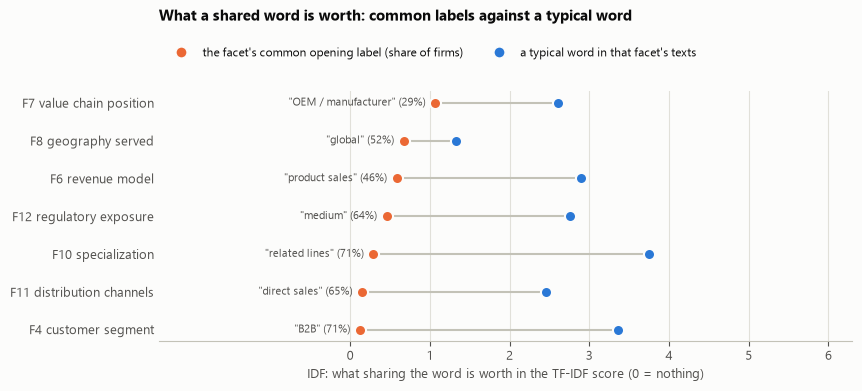

,label,share of firms,label IDF,typical word IDF (median as used),a one-firm word's IDF
facet,,,,,
F4 customer segment,B2B,0.71,0.12,3.36,5.87
F11 distribution channels,direct sales,0.65,0.15,2.46,5.87
F10 specialization,related lines,0.71,0.29,3.75,5.87
F12 regulatory exposure,medium,0.64,0.46,2.76,5.87
F6 revenue model,product sales,0.46,0.58,2.90,5.87
F8 geography served,global,0.52,0.67,1.33,5.87
F7 value chain position,OEM / manufacturer,0.29,1.07,2.60,5.87


In [7]:
import re

# each facet whose texts mostly open with the same category label (over 10% of training firms)
label_words = {}
for n in FACETS:
    pre = texts[n].reindex(training).dropna().str.extract(r"^([^:;]{1,30}):")[0].str.strip().value_counts(normalize=True)
    if len(pre) and pre.iloc[0] > 0.1:
        label_words[n] = (pre.index[0], pre.iloc[0])

rows = []
for n, (lab, share_) in label_words.items():
    idf = idfs[n]
    in_texts = [idf[w] for t in texts[n].reindex(training).dropna() for w in set(fw.tokens(t))]   # a typical word as used
    rows.append({"facet": label[n], "label": lab, "share of firms": share_,
                 "label IDF": float(np.mean([idf[w] for w in fw.tokens(lab) if w in idf])),
                 "typical word IDF (median as used)": float(np.median(in_texts)),
                 "a one-firm word's IDF": float(idf.max())})
boilerplate = pd.DataFrame(rows).set_index("facet").sort_values("label IDF")

fig, ax = plt.subplots(figsize=(9.5, 3.9))
fig.subplots_adjust(left=0.24, right=0.97, top=0.78, bottom=0.14)
y = np.arange(len(boilerplate))
ax.hlines(y, boilerplate["label IDF"], boilerplate["typical word IDF (median as used)"], color=BASE, lw=1.5, zorder=1)
ax.plot(boilerplate["label IDF"], y, "o", ms=8, mfc=TARGET_COLOR["WEN"], mec=SURFACE, mew=1.5, zorder=3)
ax.plot(boilerplate["typical word IDF (median as used)"], y, "o", ms=8, mfc=TARGET_COLOR["PCTY"], mec=SURFACE, mew=1.5, zorder=3)
for k, (lab, v, sh) in enumerate(zip(boilerplate["label"], boilerplate["label IDF"], boilerplate["share of firms"])):
    ax.text(v - 0.12, k, f"\"{lab}\" ({sh:.0%})", ha="right", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, boilerplate.index)
ax.set_xlim(-2.4, 6.3)
ax.set_xticks(range(0, 7))
ax.set_xlabel("IDF: what sharing the word is worth in the TF-IDF score (0 = nothing)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=8, mfc=TARGET_COLOR["WEN"], mec=SURFACE, label="the facet's common opening label (share of firms)"),
                    Line2D([], [], ls="", marker="o", ms=8, mfc=TARGET_COLOR["PCTY"], mec=SURFACE, label="a typical word in that facet's texts")],
           loc="upper left", bbox_to_anchor=(0.24, 0.92), ncol=2, frameon=False, fontsize=8.5)
fig.suptitle("What a shared word is worth: common labels against a typical word", x=0.24, ha="left", y=0.99,
             fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "bm25_label_idf.png", dpi=150)
plt.show()
boilerplate.round(2)

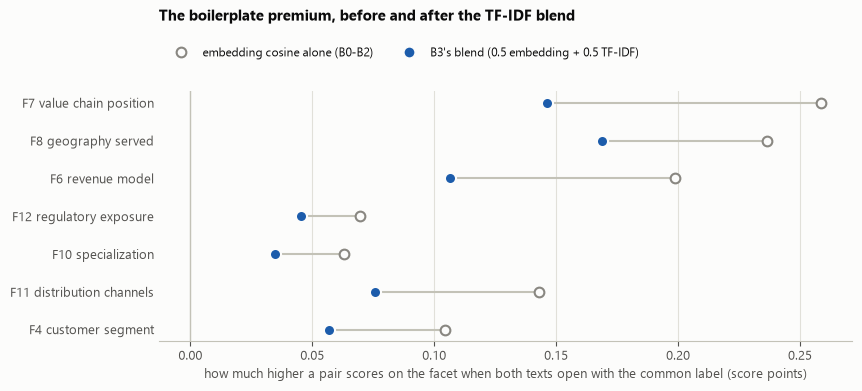

score,B3 blend,TF-IDF alone,embedding alone,B3 blend ÷ embedding
facet,,,,
F4 customer segment,0.057,0.009,0.105,0.545
F11 distribution channels,0.076,0.008,0.143,0.529
F10 specialization,0.035,0.006,0.063,0.549
F12 regulatory exposure,0.045,0.021,0.069,0.651
F6 revenue model,0.107,0.014,0.199,0.536
F8 geography served,0.169,0.101,0.237,0.714
F7 value chain position,0.146,0.034,0.259,0.566


In [8]:
# How much sharing the label raises a facet's score: mean score of training pairs that both open with the label,
# minus pairs where only one does. Embedding alone (B1/B2's score) against B3's blend (0.5 embedding + 0.5 TF-IDF).
tr_idx = np.array([pos[x] for x in training])
off_diag = ~np.eye(len(tr_idx), dtype=bool)
rows = []
for n, (lab, _) in label_words.items():
    has = texts[n].reindex(training).fillna("").str.match(rf"\s*{re.escape(lab)}\s*:").to_numpy()
    both, one = has[:, None] & has[None, :] & off_diag, (has[:, None] ^ has[None, :])
    for name, M in [("embedding alone", emb_cos[n]), ("TF-IDF alone", lex[n]), ("B3 blend", blended[n])]:
        X = M[np.ix_(tr_idx, tr_idx)]
        rows.append({"facet": label[n], "score": name, "premium": np.nanmean(X[both]) - np.nanmean(X[one])})
premium = pd.DataFrame(rows).pivot(index="facet", columns="score", values="premium").reindex(boilerplate.index)
premium["B3 blend ÷ embedding"] = premium["B3 blend"] / premium["embedding alone"]

fig, ax = plt.subplots(figsize=(9.5, 3.9))
fig.subplots_adjust(left=0.24, right=0.97, top=0.78, bottom=0.14)
y = np.arange(len(premium))
ax.hlines(y, premium["B3 blend"], premium["embedding alone"], color=BASE, lw=1.5, zorder=1)
ax.plot(premium["embedding alone"], y, "o", ms=7, mfc=SURFACE, mec=MUTED, mew=1.5, zorder=2)
ax.plot(premium["B3 blend"], y, "o", ms=8, mfc=DIRECT, mec=SURFACE, mew=1.5, zorder=3)
ax.axvline(0, color=BASE, lw=1)
ax.set_yticks(y, premium.index)
ax.set_xlabel("how much higher a pair scores on the facet when both texts open with the common label (score points)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=7, mfc=SURFACE, mec=MUTED, mew=1.5, label="embedding cosine alone (B0-B2)"),
                    Line2D([], [], ls="", marker="o", ms=8, mfc=DIRECT, mec=SURFACE, label="B3's blend (0.5 embedding + 0.5 TF-IDF)")],
           loc="upper left", bbox_to_anchor=(0.24, 0.92), ncol=2, frameon=False, fontsize=8.5)
fig.suptitle("The boilerplate premium, before and after the TF-IDF blend", x=0.24, ha="left", y=0.99,
             fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "bm25_label_premium.png", dpi=150)
plt.show()
premium.round(3)

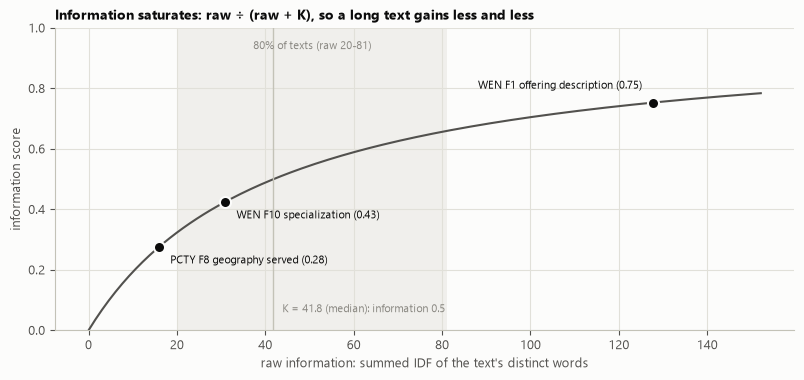

In [9]:
# Saturation: every training company-facet text, its summed IDF against its information score
raw_tr, info_tr = raw_info.reindex(training), info_score.reindex(training)
xs, ys = raw_tr.to_numpy().ravel(), info_tr.to_numpy().ravel()
keep = ~np.isnan(xs)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
fig.subplots_adjust(left=0.1, right=0.97, top=0.86, bottom=0.14)
p10, p90 = np.percentile(xs[keep], [10, 90])                  # every text lies on the curve; show where most fall
ax.axvspan(p10, p90, color=BAND, lw=0, zorder=0)
ax.text((p10 + p90) / 2, 0.93, f"80% of texts (raw {p10:.0f}-{p90:.0f})", ha="center", fontsize=8, color=MUTED)
grid_x = np.linspace(0, np.nanmax(xs) * 1.02, 200)
ax.plot(grid_x, grid_x / (grid_x + K_SAT), color=INK2, lw=1.5)
ax.axvline(K_SAT, color=BASE, lw=1)
ax.text(K_SAT + 2, 0.06, f"K = {K_SAT:.1f} (median): information 0.5", fontsize=8, color=MUTED)
for t, n in [("PCTY", "geography_served"), ("WEN", "offering_description"), ("WEN", "specialization")]:
    i = id_of[t]
    ax.plot(raw_info.at[i, n], info_score.at[i, n], "o", ms=8, mfc=INK, mec=SURFACE, mew=1.5)
    right = raw_info.at[i, n] > K_SAT * 2
    ax.annotate(f"{t} {label[n]} ({info_score.at[i, n]:.2f})", (raw_info.at[i, n], info_score.at[i, n]),
                xytext=(-8, 10) if right else (8, -12), textcoords="offset points", fontsize=8, color=INK,
                ha="right" if right else "left")
ax.set_xlabel("raw information: summed IDF of the text's distinct words")
ax.set_ylabel("information score")
ax.set_ylim(0, 1)
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Information saturates: raw ÷ (raw + K), so a long text gains less and less", loc="left")
fig.savefig(FIG_OUT / "bm25_saturation.png", dpi=150)
plt.show()

In [10]:
# One worked pair from customer segment: two firms that share only the "B2B" label, against two that share specific words
n = "customer_segment"
i_tr = [pos[x] for x in training]
has = texts[n].reindex(training).fillna("").str.match(r"\s*B2B\s*:").to_numpy()
E, L, B = (M[np.ix_(i_tr, i_tr)] for M in (emb_cos[n], lex[n], blended[n]))
pair_mask = has[:, None] & has[None, :] & off_diag
only_label = np.where(pair_mask & (L < 0.05), E - L, -np.inf)                 # high embedding, near-zero word overlap
a, b = np.unravel_index(np.argmax(only_label), only_label.shape)
specific = np.where(pair_mask, L, -np.inf)                                     # the strongest word overlap
c, d = np.unravel_index(np.argmax(specific), specific.shape)
worked = pd.DataFrame([{"pair": f"{ticker[training[x]]} – {ticker[training[y]]}", "what they share": what,
                        "text 1": texts.at[training[x], n], "text 2": texts.at[training[y], n],
                        "embedding cosine": E[x, y], "TF-IDF cosine": L[x, y], "B3 facet score": B[x, y]}
                       for x, y, what in [(a, b, "the \"B2B\" label, almost no specific words"), (c, d, "specific words")]])
with pd.option_context("display.max_colwidth", 90):
    display(worked.round(2))

,pair,what they share,text 1,text 2,embedding cosine,TF-IDF cosine,B3 facet score
0,ESAB – PSIX,"the ""B2B"" label, almost no specific words","B2B: manufacturers, fabricators, construction contractors, shipyards, energy companies","B2B: equipment manufacturers, generator set builders, material handling OEMs, vehicle ...",0.93,0.03,0.48
1,WHD – FTK,specific words,"B2B: oil and gas exploration and production operators, oilfield service companies","B2B: oil and gas exploration and production operators, oilfield service companies",1.00,1.00,1.00


**Reading.**
- **Labels are worth almost nothing.** The seven common opening labels have IDFs of 0.12–1.07. A typical word in the same facets is worth 1.3–3.8, and a word only one firm uses 5.9.
  - "B2B" (71% of firms) is worth 0.12, "direct sales" (65%) 0.15, "related lines" (71%) 0.29, "medium" regulatory exposure (64%) 0.46.
  - "OEM / manufacturer" (29%) keeps more weight, 1.07, because fewer firms use it. That is the intended behaviour: a rarer label says more.
- **B3 roughly halves the boilerplate premium.** Under the embedding alone, a pair whose texts open with the same common label scores 0.06–0.26 higher on that facet than a pair where only one does. B3's blend keeps 53–71% of that premium.
  - **Why about half:** half of B3's score is the TF-IDF cosine, where the label adds only 0.006–0.03 (geography 0.10).
  - **Geography keeps the most (71%),** because the rest of its text is generic too: its typical word is worth only 1.3 ("customers worldwide", "United States").
- **Saturation.** A text at K (raw 41.8, the median) scores 0.5. Generic texts sit low, such as PCTY's geography at 0.28 and WEN's specialization at 0.43. A long, specific text sits high, such as WEN's offering description at 0.75. Doubling a text's raw information from K raises its score only from 0.5 to 0.67.
- **The worked pair** (customer segment):
  - **ESAB and PSIX** share the "B2B" label and almost nothing specific: embedding cosine 0.93, TF-IDF 0.03, B3 facet score 0.48.
  - **WHD and FTK** have the same specific text ("oil and gas exploration and production operators, oilfield service companies"): 1.00 on all three.
- **A side effect.** The TF-IDF half also rewards shared rare words regardless of a firm's role. That is how Lamb Weston (a fries supplier) rises for WEN in section 4.

### Comp lists and their sizes

In [11]:
def select(Smat, targets, mutual=True):
    if not mutual:
        r = cd.rank_candidates(Smat, ids, targets=targets, pool=training)
        return r[r["in_top_k"]].assign(mutual=np.nan, topped_up=False)[["target", "comp", "rank", "similarity", "mutual", "topped_up"]]
    return fw.mutual_top_k(Smat, ids, targets, training, k=fw.TOP_K, min_comps=fw.MIN_COMPS)

sel_train = {name: select(Sm, training, mutual=name != B0_RULE) for name, Sm in S.items()}
sel_hold = {name: select(Sm, holdout, mutual=name != B0_RULE) for name, Sm in S.items()}


def sizes(sel_by_method, targets):
    rows = []
    for name, sel in sel_by_method.items():
        n = sel.groupby("target").size().reindex(targets, fill_value=0)
        mutual_n = sel.groupby("target")["mutual"].sum().reindex(targets, fill_value=0)
        rows.append({"method": name, "targets": len(targets), "comps (median)": n.median(), "comps (mean)": n.mean(),
                     "% targets topped up": np.nan if sel["mutual"].isna().all() else 100 * sel.groupby("target")["topped_up"].any().reindex(targets, fill_value=False).mean(),
                     "% with 0 mutual": np.nan if sel["mutual"].isna().all() else 100 * (mutual_n == 0).mean(),
                     "% with 10 mutual": np.nan if sel["mutual"].isna().all() else 100 * (mutual_n == fw.TOP_K).mean()})
    return pd.DataFrame(rows).set_index("method")

sizes(sel_train, training).round(1)

,targets,comps (median),comps (mean),% targets topped up,% with 0 mutual,% with 10 mutual
method,,,,,,
B0 one-way (v0),373,10.0,10.0,NaN,NaN,NaN
B0 mutual,373,6.0,6.2,15.5,2.4,13.4
B1: none as missing,373,6.0,6.1,17.7,2.4,12.1
B2: + information weights,373,6.0,6.2,16.9,2.9,13.1
B3: + TF-IDF blend = method 1,373,7.0,6.4,11.0,1.3,13.7


**Reading.** Mutual top 10 gives a median of 6 comps (B0–B2) or 7 (B3), and never more than 10. Between 11% (B3) and 18% (B1) of targets have fewer than 3 mutual comps and are topped up from their own top 10; 1.3–2.9% have none. 12–14% keep all 10.

## 3. Method 2: FAME's heads, gate and experts, without training

| FAME | here |
|---|---|
| each attention head scores items separately | each facet scores the pool on its own: method 1's blend, with the embedding part matched piece by piece |
| a softmax gate weights the heads, depending on the user | a fixed-rule gate weights the facets, depending on the target (below) |
| several experts within a head | the pieces of a facet written as a `;` list ("service provider: …; OEM / manufacturer: …"): each piece is matched to its best counterpart on the other side, and the facet score is the mean of those matches, both directions averaged |

### The gate rule: information **multiplied by** sharpness

For a target *t* and each facet *f* it has:

> **gate(t, f) = information(t, f) × sharpness(t, f) ÷ Σ_g [ information(t, g) × sharpness(t, g) ]**

That is: multiply the two numbers for each facet, then divide by the total over the target's facets, so the gates sum to 1 (100%).

- **information(t, f)** = raw ÷ (raw + K), as in method 1. It measures how specific the target's own text is on the facet. "B2C: consumers" scores low; a detailed product list scores high.
- **sharpness(t, f)** = (mean of *t*'s 10 highest scores on *f* over the training firms − mean of *t*'s scores on *f* over all training firms) ÷ SD of those scores, floored at 0. It measures whether a few firms clearly stand out as close to the target on this facet.
- **Why the product:** a facet only counts for much when the text is specific *and* some firms clearly match it. If either number is near 0, so is the product.

The method 2 similarity then uses the target's gate as its facet weights:

> **S₂(t, c) = Σ_f gate(t, f) × s_f(t, c) ÷ Σ_f gate(t, f)** (over the facets both have)

- **Direction:** row *t* uses *t*'s own gate, so S₂ is not symmetric, and the mutual check scores the target from each comp's side with the comp's own gate.
- **No fitting:** nothing is trained or tuned; the gate is computed from the texts and the pool.
- **Left out:** FAME's transformer, its learned item embeddings and its next-item training. We have no interaction data, and our facets are already explicit heads.

In [12]:
pc = fw.piece_cosines(texts, vectors)
per_facet_m2 = fw.blend(pc, lex)
sharp = fw.sharpness(per_facet_m2, ids, training, k=fw.TOP_K)
gates = fw.gate(info_score, sharp)
S[M2] = fw.gated_similarity(per_facet_m2, gates)
sel_train[M2] = select(S[M2], training)
sel_hold[M2] = select(S[M2], holdout)

n_pieces = texts.apply(lambda c: c.dropna().map(lambda t: len(fw.pieces(t))))
pd.DataFrame({"% with 2+ pieces": 100 * (n_pieces > 1).mean(), "pieces (median)": n_pieces.median(),
              "mean sharpness": sharp.reindex(training).mean(),
              "mean gate %": 100 * gates.reindex(training).mean(),
              "equal share %": 100 / len(FACETS)}).rename(index=label).round(2)

,% with 2+ pieces,pieces (median),mean sharpness,mean gate %,equal share %
F1 offering description,0.38,1.0,3.13,13.08,9.09
F2 primary products,82.18,4.0,3.38,9.69,9.09
F3 primary services,76.17,3.0,3.30,8.23,9.09
F4 customer segment,48.59,1.0,3.13,9.45,9.09
F5 end markets,98.50,4.0,3.54,7.38,9.09
F6 revenue model,74.86,2.0,3.00,9.93,9.09
F7 value chain position,78.80,2.0,3.05,10.67,9.09
F8 geography served,0.00,1.0,2.83,6.29,9.09
F10 specialization,0.00,1.0,2.95,8.91,9.09
F11 distribution channels,84.24,2.0,3.09,9.83,9.09


**The gate worked through for WEN and PCTY.** Each column follows the formula: information × sharpness gives the product, and the product ÷ its total gives the gate. The last check confirms the code's gate is exactly this.

In [13]:
def gate_table(t):
    tid = id_of[t]
    g = pd.DataFrame({"information": info_score.loc[tid], "sharpness": sharp.loc[tid]})
    g["information × sharpness"] = g["information"] * g["sharpness"]
    total = g["information × sharpness"].sum()
    g["gate % = product ÷ total"] = 100 * g["information × sharpness"] / total
    assert np.allclose(g["gate % = product ÷ total"].dropna(), 100 * gates.loc[tid].dropna())   # same as the code
    g = g.rename(index=label)
    g.loc["total"] = [np.nan, np.nan, total, 100.0]
    return g

pd.concat({t: gate_table(t) for t in ["WEN", "PCTY"]}, axis=1).round(3)

WEN                                                                   PCTY                                                           
                          information sharpness information × sharpness gate % = product ÷ total information sharpness information × sharpness gate % = product ÷ total
F1 offering description         0.753     3.169                   2.387                   13.000       0.624     3.659                   2.283                   12.042
F2 primary products             0.535     3.307                   1.769                    9.631       0.473     3.790                   1.792                    9.453
F3 primary services               NaN       NaN                     NaN                      NaN       0.356     3.899                   1.387                    7.319
F4 customer segment             0.493     2.998                   1.480                    8.057       0.378     3.980                   1.504                    7.934
F5 end markets                  0.348     4.200                   1.464                    7.969       0.363     3.692                   1.340                    7.071
F6 revenue model                0.658     3.901                   2.569                   13.988       0.674     3.291                   2.217                   11.696
F7 value chain position         0.649     3.505                   2.274                   12.381       0.566     3.678                   2.082                   10.982
F8 geography served             0.500     3.012                   1.507                    8.206       0.276     3.425                   0.946                    4.992
F10 specialization              0.425     2.814                   1.197                    6.516       0.524     3.601                   1.886                    9.952
F11 distribution channels       0.574     3.583                   2.056                   11.194       0.643     3.155                   2.029                   10.706
F12 regulatory exposure         0.500     3.330                   1.664                    9.059       0.441     3.374                   1.489                    7.853
total                             NaN       NaN                  18.365                  100.000         NaN       NaN                  18.955                  100.000

**Reading the worked example.**
- **One row worked through.** WEN's offering description has information 0.753 and sharpness 3.169. Their product is 0.753 × 3.169 = 2.387. Divided by WEN's total of 18.365, that gives a gate of 13.0%.
- **A facet WEN lacks.** WEN's primary services is "none", so it gets no gate, and the other ten facets share 100%.
- **Sharpness varies little.** It runs 2.8–4.2 across WEN's facets, so information mostly sets the order. PCTY's geography ("US national: …", information 0.28) gets the smallest gate, 5.0%.

### How method 2 weighs the facets for PCTY and WEN

Each facet gets two dots:
- **Gray (hollow):** the target's facet weights from **information alone**, information(t, f) ÷ its total, before sharpness is multiplied in.
- **Coloured (filled):** the **gate**, information × sharpness ÷ total.

The gap between the two dots is what sharpness changes. The vertical line is equal weights (1 ÷ 11 = 9.1%). The tables above give the same numbers.

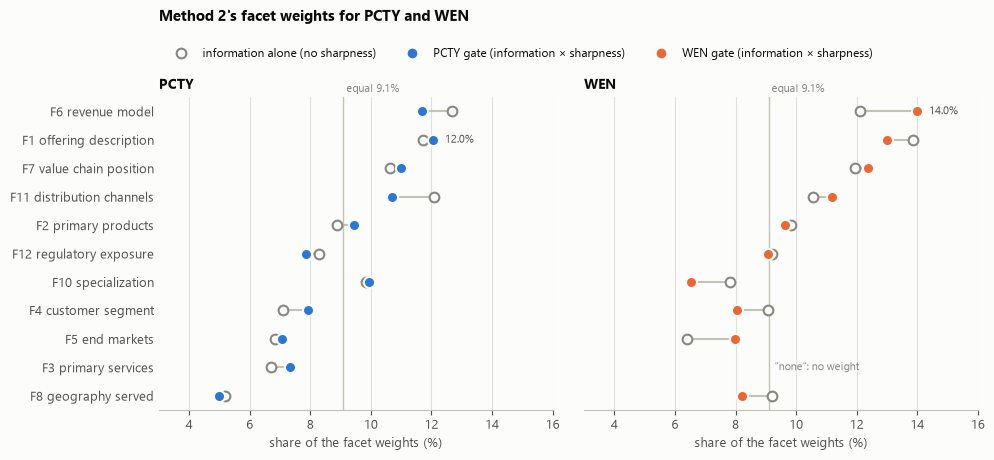

PCTY                               WEN              
                          information alone % gate % change information alone % gate % change
F6 revenue model                         12.7   11.7   -1.0                12.1   14.0    1.9
F1 offering description                  11.7   12.0    0.3                13.9   13.0   -0.9
F7 value chain position                  10.6   11.0    0.3                11.9   12.4    0.4
F11 distribution channels                12.1   10.7   -1.4                10.6   11.2    0.6
F2 primary products                       8.9    9.5    0.6                 9.8    9.6   -0.2
F12 regulatory exposure                   8.3    7.9   -0.4                 9.2    9.1   -0.1
F10 specialization                        9.9   10.0    0.1                 7.8    6.5   -1.3
F4 customer segment                       7.1    7.9    0.8                 9.1    8.1   -1.0
F5 end markets                            6.8    7.1    0.2                 6.4    8.0    1.6
F3 primary services                       6.7    7.3    0.6                 NaN    NaN    NaN
F8 geography served                       5.2    5.0   -0.2                 9.2    8.2   -1.0

In [14]:
gate_pct = {t: 100 * gates.loc[id_of[t]] for t in EXAMPLES}
info_pct = {t: 100 * info_score.loc[id_of[t]] / info_score.loc[id_of[t]].sum() for t in EXAMPLES}
order = pd.concat(gate_pct, axis=1).mean(axis=1).sort_values().index          # facets, lowest gate first
EQUAL = 100 / len(FACETS)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
fig.subplots_adjust(left=0.2, right=0.98, top=0.8, bottom=0.12, wspace=0.08)
for ax, t in zip(axes, EXAMPLES):
    y = np.arange(len(order))
    g, inf = gate_pct[t].reindex(order), info_pct[t].reindex(order)
    ax.axvline(EQUAL, color=BASE, lw=1, zorder=0)
    ax.hlines(y, inf, g, color=BASE, lw=1.5, zorder=1)
    ax.plot(inf, y, "o", ms=7, mfc=SURFACE, mec=MUTED, mew=1.5, zorder=2)
    ax.plot(g, y, "o", ms=8, mfc=TARGET_COLOR[t], mec=SURFACE, mew=1.5, zorder=3)
    for k in np.flatnonzero(g.isna().to_numpy()):
        ax.text(EQUAL + 0.2, k, "\"none\": no weight", va="center", fontsize=8, color=MUTED)
    top = g.dropna().sort_values().index[-1]
    ax.text(g[top] + 0.4, list(order).index(top), f"{g[top]:.1f}%", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, [label[n] for n in order])
    ax.set_xlim(3, 16)
    ax.set_xlabel("share of the facet weights (%)")
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"{t}", loc="left")
    ax.text(EQUAL, len(order) - 0.4, " equal 9.1%", fontsize=8, color=MUTED, va="bottom")
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=7, mfc=SURFACE, mec=MUTED, mew=1.5, label="information alone (no sharpness)"),
                    Line2D([], [], ls="", marker="o", ms=8, mfc=TARGET_COLOR["PCTY"], mec=SURFACE, label="PCTY gate (information × sharpness)"),
                    Line2D([], [], ls="", marker="o", ms=8, mfc=TARGET_COLOR["WEN"], mec=SURFACE, label="WEN gate (information × sharpness)")],
           loc="upper left", bbox_to_anchor=(0.2, 0.93), ncol=3, frameon=False, fontsize=8.5)
fig.suptitle("Method 2's facet weights for PCTY and WEN", x=0.2, ha="left", y=0.99, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "m2_facet_weights_pcty_wen.png", dpi=150)
plt.show()
pd.concat({t: pd.DataFrame({"information alone %": info_pct[t], "gate %": gate_pct[t], "change": gate_pct[t] - info_pct[t]})
           for t in EXAMPLES}, axis=1).reindex(order[::-1]).rename(index=label).round(1)

**Reading: which facets method 2 treats as important.**
- **Shared priorities.** Both targets' gates rank the same four facets highest, between 10.7% and 14.0%: revenue model, offering description, value chain position and distribution channels. These are the facets where the texts are most specific.
- **Where PCTY and WEN differ:**
  - **WEN** leans hardest on revenue model (14.0%) and offering description (13.0%). Specialization gets the least (6.5%): its information is low (0.43), and sharpness lowers it further.
  - **PCTY's** top gate is offering description (12.0%), just ahead of revenue model (11.7%). It gives more to specialization than WEN does (10.0%) and much less to geography (5.0%, "US national: serves employers across the United States").
- **What sharpness changes** (gray dot → coloured dot). Every shift is under 2 points, so the gate stays close to information alone.
  - **WEN:** sharpness raises revenue model (+1.9) and end markets (+1.6), the facets where a few firms stand out most clearly. It lowers specialization (−1.3), customer segment and geography (−1.0 each).
  - **PCTY:** it lowers distribution channels (−1.4) and revenue model (−1.0), and nudges customer segment, primary products and primary services up (+0.6–0.8).

In [15]:
GATE_EXAMPLES = ["PCTY", "WEN", "CSL", "AFG"]
(100 * gates.loc[[id_of[t] for t in GATE_EXAMPLES]].set_axis(GATE_EXAMPLES).T).rename(index=label).round(1)

,PCTY,WEN,CSL,AFG
F1 offering description,12.0,13.0,14.8,13.3
F2 primary products,9.5,9.6,13.9,11.9
F3 primary services,7.3,NaN,NaN,6.1
F4 customer segment,7.9,8.1,8.5,11.5
F5 end markets,7.1,8.0,6.3,6.6
F6 revenue model,11.7,14.0,7.9,10.9
F7 value chain position,11.0,12.4,12.0,9.5
F8 geography served,5.0,8.2,6.2,4.6
F10 specialization,10.0,6.5,11.8,8.1
F11 distribution channels,10.7,11.2,10.3,9.2


**Reading.**
- **Pieces.** Products, services, end markets, revenue model, value chain and distribution are `;` lists for 75–98% of firms, so the piece matching applies there. Offering description, geography, specialization and regulatory exposure are single pieces, and their score is unchanged.
- **The gate follows information.** Mean sharpness is 2.8–3.5 SD on every facet, so information drives the gate: on average 13.1% for offering description down to 6.3% for geography.
- **Little difference between targets.** Revenue model gets 14.0% for WEN against 7.9% for CSL, and primary products 13.9% for CSL against 9.5% for PCTY. These are small shifts, so M2's lists are close to B3's.

In [16]:
sizes(sel_train, training).round(1)

,targets,comps (median),comps (mean),% targets topped up,% with 0 mutual,% with 10 mutual
method,,,,,,
B0 one-way (v0),373,10.0,10.0,NaN,NaN,NaN
B0 mutual,373,6.0,6.2,15.5,2.4,13.4
B1: none as missing,373,6.0,6.1,17.7,2.4,12.1
B2: + information weights,373,6.0,6.2,16.9,2.9,13.1
B3: + TF-IDF blend = method 1,373,7.0,6.4,11.0,1.3,13.7
M2: gate + pieces = method 2,373,7.0,6.6,10.5,1.3,15.5


In [17]:
# Diagnostic only, not a method: the same similarities with v0's one-way top 10, so section 6 can separate the
# list rule (mutual, shorter lists) from the weighting. Fixed here, before any multiple is read.
diag_train = {f"diagnostic: {name.split(' = ')[1]}, one-way top 10": select(S[name], training, mutual=False)
              for name in (M1, M2)}

## 4. The reviewers' golden set

**Rule for using the reviewers' scores (agreed 2026-11-03):**
1. **Source:** only the three reviewers' scores (Riya, Barbara, Matthew) on the 36 PCTY/WEN pairs (`reviewer_labels_20261028.json`). Grades: 2 = direct comp, 1 = adjacent, 0 = not a comp. No Sol or Haiku verdict enters this set.
2. **Main set (majority):** a pair's grade is the one at least 2 of the 3 reviewers gave. Pairs with three different grades are left out and listed as "no majority".
3. **Strict check (unanimous):** the pairs all three graded the same, reported separately.
4. **Unlabeled comps:** a comp in a method's list that no reviewer scored is *unlabeled*, never 0. Every metric comes with the share of the list that is labeled.
5. **Metrics:** precision@10 (share graded 1 or 2) and NDCG@10 (`golden_set.py`) on the labeled comps of each list. Beside them, as analysis:
   - which reviewed comps each list finds;
   - where every reviewed comp ranks;
   - a facet-by-facet view of WEN;
   - each reviewer on their own (a robustness check, not a replacement for the majority).
6. **Caveat:** the majority mostly reflects Barbara and Matthew, who agree on 30 of 36 pairs. Riya agrees with either of them on 12.

The 36 pairs were pooled from v0's four routes, so the new methods' lists contain comps nobody has scored. Section 8 writes those pairs to a sheet for the reviewers.

In [18]:
snapshot = json.loads((V1 / "golden_set/labels/reviewer_labels_20261028.json").read_text(encoding="utf-8"))
reviewer_labels = pd.DataFrame(snapshot["labels"])
majority, unanimous, no_majority = se.reviewer_sets(reviewer_labels)
print(f"snapshot fetched {snapshot['fetched_at_utc']}: {len(reviewer_labels)} pairs; majority set {len(majority)}, "
      f"unanimous {len(unanimous)}, no majority {len(no_majority)}")
pd.concat({"majority": majority.groupby([majority["target"].map(ticker), "grade"]).size(),
           "unanimous": unanimous.groupby([unanimous["target"].map(ticker), "grade"]).size()}, axis=1).fillna(0).astype(int)

snapshot fetched 2026-10-28T11:25:10.429Z: 36 pairs; majority set 32, unanimous 11, no majority 4


majority  unanimous
target grade                     
PCTY   0             5          0
       1             4          1
       2             3          3
WEN    0            16          7
       1             3          0
       2             1          0

### The hits, at a glance

**What each method lists.** One bar per method, one segment per comp in its list, coloured by the reviewers' majority grade:
- **dark blue:** direct comp (2);
- **light blue:** adjacent (1);
- **gray:** no majority grade, or not yet reviewed;
- **red:** not a comp (0).

A good list is all blue. The text after each bar counts the good comps found, out of all those the reviewers graded 1 or 2, and the non-comps listed.

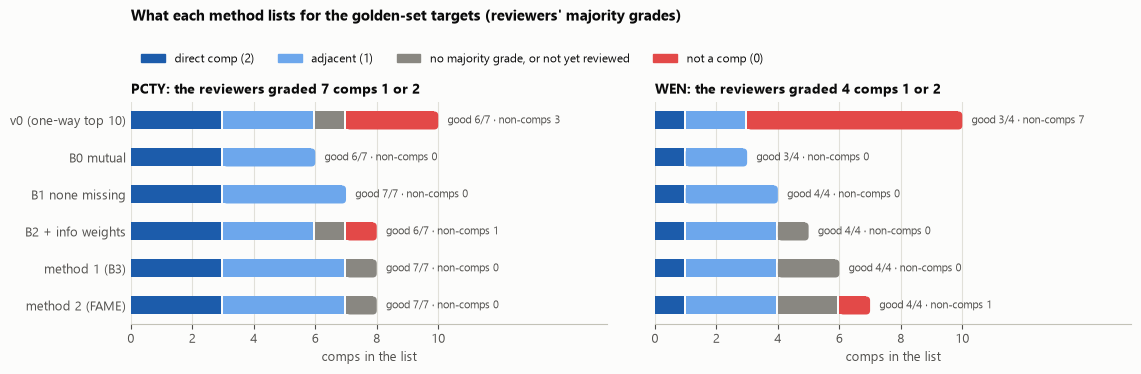

In [19]:
grade_of = {(r.target, r.comp): str(r.grade) for r in majority.itertuples()}
grade_of.update({(r.target, r.comp): "split" for r in no_majority.itertuples()})
reviewed_grades = pd.concat([majority.assign(grade=majority["grade"].astype(str)),
                             no_majority[["target", "comp"]].assign(grade="split")])
full_rank = {name: cd.rank_candidates(Sm, ids, targets=[id_of[t] for t in EXAMPLES], pool=training)
             for name, Sm in S.items()}
METHODS = list(sel_train)
KINDS = [("2", "direct comp (2)", DIRECT), ("1", "adjacent (1)", ADJACENT),
         ("?", "no majority grade, or not yet reviewed", NEUTRAL), ("0", "not a comp (0)", NONCOMP)]


def kind(t, c):
    g = grade_of.get((t, c), "?")
    return "?" if g == "split" else g


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), sharey=True)
fig.subplots_adjust(left=0.12, right=0.99, top=0.74, bottom=0.14, wspace=0.1)
for ax, t in zip(axes, EXAMPLES):
    tid = id_of[t]
    ax.set_xlim(0, 15.5)
    ax.set_ylim(len(METHODS) - 0.5, -0.5)
    good_total = int((majority.loc[majority["target"] == tid, "grade"] >= 1).sum())
    for k, name in enumerate(METHODS):
        comps = sel_train[name].loc[lambda d: d["target"] == tid, "comp"]
        counts = pd.Series([kind(tid, c) for c in comps]).value_counts()
        stacked_hbar(ax, k, [(counts.get(code, 0), color) for code, _, color in KINDS])
        good = int(counts.get("2", 0) + counts.get("1", 0))
        ax.text(len(comps) + 0.3, k, f"good {good}/{good_total} · non-comps {int(counts.get('0', 0))}",
                va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(METHODS)), [SHORT[m].replace("\n", " ") for m in METHODS])
    ax.set_xticks(range(0, 11, 2))
    ax.set_xlabel("comps in the list")
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"{t}: the reviewers graded {good_total} comps 1 or 2", loc="left")
fig.legend(handles=[Patch(color=c, label=l) for _, l, c in KINDS], loc="upper left", bbox_to_anchor=(0.12, 0.9),
           ncol=4, frameon=False, fontsize=8.5)
fig.suptitle("What each method lists for the golden-set targets (reviewers' majority grades)", x=0.12, ha="left",
             y=0.99, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "golden_hits_by_method.png", dpi=150)
plt.show()

**Where every reviewed comp ranks, method by method.** Each line is one reviewed comp, followed from v0 (left) to method 2 (right). The y-axis is its rank among the 372 other training firms, best at the top, and the shaded band is the top 10.
- **Line colour:** blue for good comps (dark = direct, light = adjacent), dark gray for no majority, light gray for non-comps.
- **Filled dot:** the comp is in that method's list. A **red dot** is a non-comp that got listed.
- **Hollow blue dot:** a good comp the method missed.
- **Labels:** every comp is named on the left at its v0 rank. On the right, the good comps and any comp listed by method 2 are named.

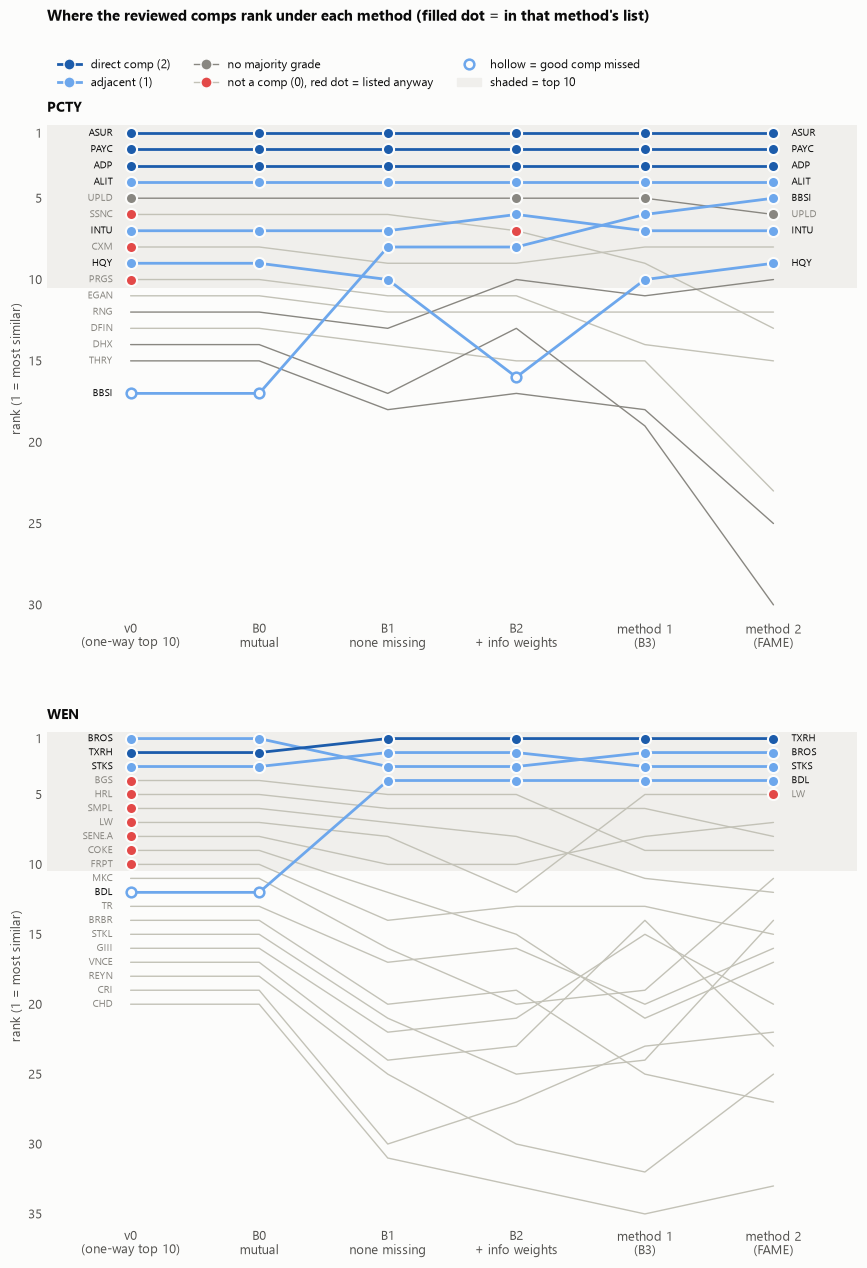

In [20]:
LINE_OF = {"2": DIRECT, "1": ADJACENT, "split": NEUTRAL, "0": BASE}
DRAW_ORDER = {"0": 0, "split": 1, "1": 2, "2": 3}
fig, axes = plt.subplots(2, 1, figsize=(10, 13))
fig.subplots_adjust(left=0.09, right=0.9, top=0.9, bottom=0.05, hspace=0.22)
x = np.arange(len(METHODS))
for ax, t in zip(axes, EXAMPLES):
    tid = id_of[t]
    rev = reviewed_grades[reviewed_grades["target"] == tid]
    ranks = pd.DataFrame({m: full_rank[m].loc[lambda d: d["target"] == tid].set_index("comp")["rank"].reindex(rev["comp"]).to_numpy()
                          for m in METHODS}, index=rev["comp"].to_numpy())
    listed = pd.DataFrame({m: rev["comp"].isin(set(sel_train[m].loc[lambda d: d["target"] == tid, "comp"])).to_numpy()
                           for m in METHODS}, index=rev["comp"].to_numpy())
    ymax = int(ranks.max().max())
    ax.axhspan(0.5, 10.5, color=BAND, lw=0, zorder=0)
    for c, g in sorted(zip(rev["comp"], rev["grade"]), key=lambda p: DRAW_ORDER[p[1]]):
        r = ranks.loc[c].to_numpy(dtype=float)
        good = g in ("1", "2")
        ax.plot(x, r, color=LINE_OF[g], lw=2 if good else 1, zorder=3 if good else 1, solid_capstyle="round")
        for xi, ri, li in zip(x, r, listed.loc[c]):
            if li:
                ax.plot(xi, ri, "o", ms=8, mfc=NONCOMP if g == "0" else LINE_OF[g], mec=SURFACE, mew=1.5, zorder=5)
            elif good:
                ax.plot(xi, ri, "o", ms=7, mfc=SURFACE, mec=LINE_OF[g], mew=1.8, zorder=4)
        ax.text(-0.14, r[0], ticker[c], ha="right", va="center", fontsize=7.5, color=INK if good else MUTED)
        if good or listed.loc[c, M2]:
            ax.text(x[-1] + 0.14, r[-1], ticker[c], ha="left", va="center", fontsize=7.5, color=INK if good else MUTED)
    ax.set_xlim(-0.65, len(METHODS) - 0.35)
    ax.set_ylim(ymax + 0.8, 0.2)
    ax.set_xticks(x, [SHORT[m] for m in METHODS])
    ax.set_yticks([1, 5, 10, 15, 20, 25, 30, 35][: 1 + ymax // 5])
    ax.set_ylabel("rank (1 = most similar)")
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(f"{t}", loc="left")
handles = [Line2D([], [], color=DIRECT, lw=2, marker="o", ms=8, mec=SURFACE, label="direct comp (2)"),
           Line2D([], [], color=ADJACENT, lw=2, marker="o", ms=8, mec=SURFACE, label="adjacent (1)"),
           Line2D([], [], color=NEUTRAL, lw=1, marker="o", ms=8, mec=SURFACE, label="no majority grade"),
           Line2D([], [], color=BASE, lw=1, marker="o", ms=8, mfc=NONCOMP, mec=SURFACE, label="not a comp (0), red dot = listed anyway"),
           Line2D([], [], ls="", marker="o", ms=7, mfc=SURFACE, mec=ADJACENT, mew=1.8, label="hollow = good comp missed"),
           Patch(color=BAND, label="shaded = top 10")]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.09, 0.955), ncol=3, frameon=False, fontsize=8.5)
fig.suptitle("Where the reviewed comps rank under each method (filled dot = in that method's list)", x=0.09, ha="left",
             y=0.985, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "golden_ranks_by_method.png", dpi=150)
plt.show()

**Reading the two charts.**
- **PCTY.**
  - v0's list ends in three red segments (SSNC, CXM, PRGS) and misses BBSI, the hollow dot at rank 17.
  - From B1 on, BBSI's line climbs into the top 10 (rank 8, then 6 under method 1 and 5 under method 2). Treating "none" as missing removes the penalty from its "none" products.
  - B1, method 1 and method 2 list only blue, plus UPLD in gray, where the reviewers split.
- **WEN.**
  - v0's list is 7 of 10 red (packaged-food and beverage makers).
  - Their red dots disappear at **B0 mutual**, but their gray lines stay inside the shaded top 10: they are still similar to WEN by score, and are dropped only because WEN isn't in *their* top 10.
  - From B1 on, BDL's line jumps from 12 to 4 and the list holds all four good comps.
  - Method 1 adds two gray comps nobody has reviewed yet (HQI, PLNT). Method 2 adds Lamb Weston (red), whose line climbs to rank 5 once the TF-IDF blend comes in.
- **B2 (information weights without the blend)** briefly drops HQY to rank 16 (hollow) and lets SSNC in for PCTY. The blend in method 1 restores both.

In [21]:
rows = []
for name, sel in sel_train.items():
    m = se.list_metrics(sel, majority).assign(method=name)
    rows.append(m)
reviewer_metrics = pd.concat(rows, ignore_index=True)
reviewer_metrics["target"] = reviewer_metrics["target"].map(ticker)
reviewer_view = reviewer_metrics.pivot(index="method", columns="target",
                                       values=["listed", "labeled share", "precision@10", "NDCG@10"]).reindex(list(sel_train))
reviewer_view.round(2)

listed       labeled share       precision@10      NDCG@10      
target                          PCTY   WEN          PCTY   WEN         PCTY  WEN    PCTY   WEN
method                                                                                        
B0 one-way (v0)                 10.0  10.0          0.90  1.00         0.67  0.3    0.93  0.78
B0 mutual                        6.0   3.0          1.00  1.00         1.00  1.0    0.94  0.78
B1: none as missing              7.0   4.0          1.00  1.00         1.00  1.0    1.00  1.00
B2: + information weights        8.0   5.0          0.88  0.80         0.86  1.0    0.94  1.00
B3: + TF-IDF blend = method 1    8.0   6.0          0.88  0.67         1.00  1.0    1.00  1.00
M2: gate + pieces = method 2     8.0   7.0          0.88  0.71         1.00  0.8    1.00  1.00

In [22]:
strict = pd.concat([se.strict_check(sel, unanimous).assign(method=name) for name, sel in sel_train.items()])
strict["target"] = strict["target"].map(ticker)
strict.pivot(index="method", columns="target",
             values=["agreed comps listed", "agreed non-comps listed"]).reindex(list(sel_train))

agreed comps listed     agreed non-comps listed    
target                                       PCTY WEN                    PCTY WEN
method                                                                           
B0 one-way (v0)                                 4   0                       0   1
B0 mutual                                       4   0                       0   0
B1: none as missing                             4   0                       0   0
B2: + information weights                       3   0                       0   0
B3: + TF-IDF blend = method 1                   4   0                       0   0
M2: gate + pieces = method 2                    4   0                       0   0

In [23]:
# each method's list for the two targets: ticker (majority grade; "split" = no majority; "·" = unlabeled; "+" = topped up)
def lists(t):
    cols = {}
    for name, sel in sel_train.items():
        d = sel[sel["target"] == id_of[t]].sort_values("rank").head(10)
        cols[name] = pd.Series([f"{ticker[c]} ({grade_of.get((id_of[t], c), '·')}){'+' if up else ''}"
                                for c, up in zip(d["comp"], d["topped_up"])], index=range(1, len(d) + 1))
    return pd.DataFrame(cols).fillna("")

display(lists("PCTY"))
display(lists("WEN"))

,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1,M2: gate + pieces = method 2
1,ASUR (2),ASUR (2),ASUR (2),ASUR (2),ASUR (2),ASUR (2)
2,PAYC (2),PAYC (2),PAYC (2),PAYC (2),PAYC (2),PAYC (2)
3,ADP (2),ADP (2),ADP (2),ADP (2),ADP (2),ADP (2)
4,ALIT (1),ALIT (1),ALIT (1),ALIT (1),ALIT (1),ALIT (1)
5,UPLD (split),INTU (1),INTU (1),UPLD (split),UPLD (split),BBSI (1)
6,SSNC (0),HQY (1),BBSI (1),INTU (1),BBSI (1),UPLD (split)
7,INTU (1),,HQY (1),SSNC (0),INTU (1),INTU (1)
8,CXM (0),,,BBSI (1),HQY (1),HQY (1)
9,HQY (1),,,,,
10,PRGS (0),,,,,


,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1,M2: gate + pieces = method 2
1,BROS (1),BROS (1),TXRH (2),TXRH (2),TXRH (2),TXRH (2)
2,TXRH (2),TXRH (2),STKS (1),STKS (1),BROS (1),BROS (1)
3,STKS (1),STKS (1),BROS (1),BROS (1),STKS (1),STKS (1)
4,BGS (0),,BDL (1),BDL (1),BDL (1),BDL (1)
5,HRL (0),,,HQI (·),HQI (·),LW (0)
6,SMPL (0),,,,PLNT (·),HQI (·)
7,LW (0),,,,,PLNT (·)
8,SENE.A (0),,,,,
9,COKE (0),,,,,
10,FRPT (0),,,,,


**Reading (2 targets, so an illustration rather than proof).**
- **WEN.** v0's list (B0 one-way) puts seven majority non-comps after BROS, TXRH and STKS: packaged-food and beverage makers BGS, HRL, SMPL, LW (Lamb Weston), SENE.A, COKE and FRPT. One of them is a unanimous non-comp.
  - The mutual filter alone (B0 mutual) drops them but keeps only 3 comps.
  - Treating "none" as missing (B1) also brings in BDL (Flanigan's).
  - B1, B2 and B3 list all four of WEN's majority comps (TXRH direct; BROS, STKS and BDL adjacent) with precision 1.0. M2 adds LW (0), so its precision is 0.8.
- **PCTY.** v0 lists SSNC, CXM and PRGS (all 0), giving precision 0.67. B0 mutual, B1, B3 and M2 reach 1.0, and every method except B2 keeps all 4 unanimous comps.
- **NDCG@10.** PCTY goes from 0.93 to 1.0 under B1, B3 and M2; WEN from 0.78 to 1.0 under B1–M2.
- **Unlabeled comps.** WEN's B3 and M2 lists add HQI (HireQuest, staffing) and PLNT (Planet Fitness). Both are franchisors, so they share WEN's franchise model but not its business; they are in section 8's sheet. UPLD's reviewers split three ways, so it counts as unlabeled.

### Which reviewed comps each method finds

Counted against the majority set:
- **good:** comps graded 1 or 2;
- **direct:** comps graded 2;
- **non-comps:** comps graded 0.

The numbers read "found / reviewed". Remember the reviewed comps were pooled from v0's four routes, so "found" means found among the comps the team looked at.

In [24]:
found = reviewer_metrics.assign(
    good=reviewer_metrics["good listed"].astype(str) + " / " + reviewer_metrics["good total"].astype(str),
    direct=reviewer_metrics["direct listed"].astype(str) + " / " + reviewer_metrics["direct total"].astype(str),
    **{"non-comps listed": reviewer_metrics["non-comps listed"].astype(str) + " / "
       + reviewer_metrics["target"].map(majority.assign(t=majority["target"].map(ticker)).query("grade == 0").groupby("t").size()).astype(str)})
found.pivot(index="method", columns="target", values=["good", "direct", "non-comps listed", "listed"]).reindex(list(sel_train))

good        direct        non-comps listed         listed    
target                          PCTY    WEN   PCTY    WEN             PCTY     WEN   PCTY WEN
method                                                                                       
B0 one-way (v0)                6 / 7  3 / 4  3 / 3  1 / 1            3 / 5  7 / 16     10  10
B0 mutual                      6 / 7  3 / 4  3 / 3  1 / 1            0 / 5  0 / 16      6   3
B1: none as missing            7 / 7  4 / 4  3 / 3  1 / 1            0 / 5  0 / 16      7   4
B2: + information weights      6 / 7  4 / 4  3 / 3  1 / 1            1 / 5  0 / 16      8   5
B3: + TF-IDF blend = method 1  7 / 7  4 / 4  3 / 3  1 / 1            0 / 5  0 / 16      8   6
M2: gate + pieces = method 2   7 / 7  4 / 4  3 / 3  1 / 1            0 / 5  1 / 16      8   7

### Where each reviewed comp ranks under each method

Rows are the reviewed comps, best majority grade first ("split" = no majority). Each cell is the comp's **rank among the 372 other training firms** under that method's similarity, with a mark for the list:
- **✓** in the list (mutual, or in v0's one-way top 10);
- **+** in the list by the top-up to 3;
- **×** in the top 10 but dropped because it isn't mutual;
- **no mark:** outside the top 10.

So a good comp should show a small number with ✓, and a non-comp a large number or ×.

In [25]:
rank_views = {}
for t in EXAMPLES:
    m = se.rank_matrix(full_rank, sel_train, reviewed_grades, id_of[t])
    m.index = m.index.set_levels(m.index.levels[0].map(ticker), level="comp")
    rank_views[t] = m
    print(t)
    display(m)

PCTY


,,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1,M2: gate + pieces = method 2
comp,grade,,,,,,
ASUR,2,1✓,1✓,1✓,1✓,1✓,1✓
ADP,2,3✓,3✓,3✓,3✓,3✓,3✓
PAYC,2,2✓,2✓,2✓,2✓,2✓,2✓
BBSI,1,17,17,8✓,8✓,6✓,5✓
HQY,1,9✓,9✓,10✓,16,10✓,9✓
INTU,1,7✓,7✓,7✓,6✓,7✓,7✓
ALIT,1,4✓,4✓,4✓,4✓,4✓,4✓
DHX,split,14,14,17,13,19,30
RNG,split,12,12,13,10×,11,10×


WEN


,,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1,M2: gate + pieces = method 2
comp,grade,,,,,,
TXRH,2,2✓,2✓,1✓,1✓,1✓,1✓
BDL,1,12,12,4✓,4✓,4✓,4✓
STKS,1,3✓,3✓,2✓,2✓,3✓,3✓
BROS,1,1✓,1✓,3✓,3✓,2✓,2✓
SENE.A,0,8✓,8×,10×,10×,8×,7×
VNCE,0,17,17,24,23,14,23
FRPT,0,10✓,10×,14,13,13,15
BGS,0,4✓,4×,5×,5×,9×,9×
STKL,0,15,15,21,25,24,14


### Why WEN's list changed: its reviewed comps, facet by facet

Each reviewed WEN comp's **B0 embedding cosine on each facet**. Under B0, a "none" facet is embedded as the word "none", so two "none"s score 1.00. The last columns give the combined similarity under B0, B1, method 1 and method 2.

In [26]:
wid = id_of["WEN"]
wen = reviewed_grades[reviewed_grades["target"] == wid]
wen = wen.sort_values("grade", key=lambda s: s.map({"2": 0, "1": 1, "split": 2, "0": 3}), kind="stable")
i = pos[wid]
facet_view = pd.DataFrame({label[n]: [per_facet_v0[n][i, pos[c]] for c in wen["comp"]] for n in FACETS},
                          index=pd.MultiIndex.from_arrays([wen["comp"].map(ticker), wen["grade"]], names=["comp", "grade"]))
for name in [B0_RULE, "B1: none as missing", M1, M2]:
    facet_view[f"S: {name.split(':')[0].split(' (')[0]}"] = [S[name][i, pos[c]] for c in wen["comp"]]
print(f"WEN's primary services: {texts_v0.at[wid, 'primary_services']!r} (B0) -> {texts.at[wid, 'primary_services']!r} (B1 on)")
print(f"reviewed WEN comps whose primary services is also 'none': "
      f"{', '.join(ticker[c] for c in wen['comp'] if texts_v0.at[c, 'primary_services'] == cd.NOT_APPLICABLE_TEXT)}")
facet_view.round(2)

WEN's primary services: 'none' (B0) -> None (B1 on)
reviewed WEN comps whose primary services is also 'none': BROS, SENE.A, VNCE, FRPT, BGS, STKL, GIII, TR, COKE, REYN, BRBR, SMPL, MKC, LW, CRI, HRL, CHD


,,F1 offering description,F2 primary products,F3 primary services,F4 customer segment,F5 end markets,F6 revenue model,F7 value chain position,F8 geography served,F10 specialization,F11 distribution channels,F12 regulatory exposure,S: B0 one-way,S: B1,S: B3,S: M2
comp,grade,,,,,,,,,,,,,,,
TXRH,2,0.60,0.74,0.05,0.82,0.87,0.97,0.65,0.81,0.79,0.81,0.75,0.72,0.78,0.54,0.54
BDL,1,0.53,0.70,0.08,0.64,0.51,0.95,0.62,0.44,0.56,0.81,0.69,0.59,0.64,0.41,0.41
STKS,1,0.58,0.67,0.07,0.77,0.70,0.91,0.63,0.76,0.47,0.81,0.77,0.65,0.71,0.46,0.46
BROS,1,0.52,0.61,1.00,0.88,0.70,0.89,0.78,0.49,0.65,0.78,0.75,0.73,0.70,0.47,0.48
SENE.A,0,0.50,0.67,1.00,0.70,0.65,0.64,0.49,0.49,0.47,0.51,0.66,0.62,0.58,0.33,0.35
VNCE,0,0.28,0.43,1.00,0.63,0.40,0.69,0.60,0.60,0.37,0.69,0.54,0.57,0.52,0.30,0.28
FRPT,0,0.42,0.55,1.00,0.62,0.51,0.61,0.66,0.58,0.58,0.48,0.61,0.60,0.56,0.31,0.30
BGS,0,0.50,0.68,1.00,0.64,0.59,0.63,0.75,0.63,0.43,0.53,0.72,0.65,0.61,0.33,0.33
STKL,0,0.41,0.32,1.00,0.67,0.72,0.60,0.48,0.57,0.35,0.51,0.67,0.57,0.53,0.28,0.30


**Reading.**
- **F3 under B0.** WEN's primary services is "none", and so is it for 17 of its 20 reviewed comps, every food maker included. Under B0 they all score 1.00 on F3, while TXRH, BDL and STKS, which list real services, score 0.05–0.08.
- **What B1 does.** Skipping F3 lifts the three restaurants and lowers the food makers. The worst good comp (BDL, 0.64) now scores above the best non-comp (BGS, 0.61); under B0, BDL at 0.59 sat below eight of them.
- **The facet that separates best.** Revenue model (F6) scores 0.89–0.97 for the four good comps and 0.45–0.71 for all 16 non-comps (food makers and apparel firms alike).

### Which facets set the good comps apart under method 2

Method 2's similarity is a sum of per-facet parts:

> **S₂(t, c) = Σ_f contribution_f**, where **contribution_f = gate(t, f) × s_f(t, c) ÷ Σ gate(t, f)** over the facets both have

For each facet, the bar is the average contribution for the reviewers' good comps (graded 1 or 2) **minus** the average for their non-comps (graded 0). A long bar means that facet does much of the work of lifting the good comps above the non-comps; a bar left of 0 means the facet favours the non-comps. The bars add up to the gap in average similarity, given in each panel's title. Facets are in the same order as the weight chart in section 3.

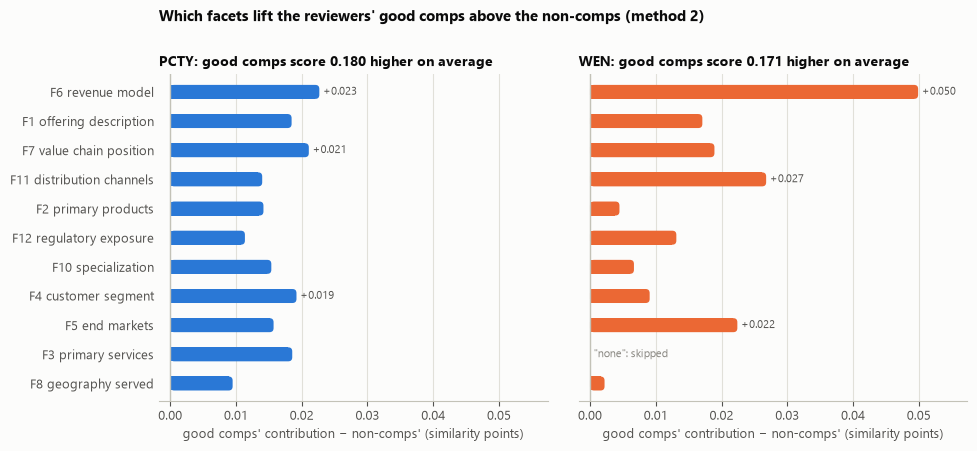

,PCTY,WEN
F1 offering description,0.018,0.017
F2 primary products,0.014,0.004
F3 primary services,0.019,0.000
F4 customer segment,0.019,0.009
F5 end markets,0.016,0.022
F6 revenue model,0.023,0.050
F7 value chain position,0.021,0.019
F8 geography served,0.009,0.002
F10 specialization,0.015,0.007
F11 distribution channels,0.014,0.027


In [27]:
def contributions(t):
    tid, i = id_of[t], pos[id_of[t]]
    w = gates.loc[tid]
    rev = reviewed_grades[(reviewed_grades["target"] == tid) & reviewed_grades["grade"].isin(["0", "1", "2"])]
    rows = {}
    for c, g in zip(rev["comp"], rev["grade"]):
        s = pd.Series({f: per_facet_m2[f][i, pos[c]] for f in FACETS})
        shared = s.notna() & w.notna()
        part = (w[shared] * s[shared] / w[shared].sum()).reindex(FACETS).fillna(0.0)
        assert np.isclose(part.sum(), S[M2][i, pos[c]])            # the parts add up to method 2's similarity
        rows[(ticker[c], g)] = part
    return pd.DataFrame(rows).T


separation = {}
for t in EXAMPLES:
    con = contributions(t)
    grades_ = con.index.get_level_values(1)
    separation[t] = con[grades_.isin(["1", "2"])].mean() - con[grades_ == "0"].mean()
separation = pd.DataFrame(separation)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
fig.subplots_adjust(left=0.2, right=0.97, top=0.84, bottom=0.13, wspace=0.08)
lim = 1.15 * separation.abs().max().max()
lo = min(0.0, separation.min().min()) * 1.3 - 0.03 * lim
for ax, t in zip(axes, EXAMPLES):
    ax.set_xlim(lo, lim)
    ax.set_ylim(-0.6, len(order) - 0.4)
    vals = separation[t].reindex(order)
    for k, v in enumerate(vals):
        hbar(ax, k, 0, v, TARGET_COLOR[t], height_px=14)
        if pd.isna(gates.loc[id_of[t], order[k]]):
            ax.text(0.01 * lim, k, "\"none\": skipped", va="center", fontsize=8, color=MUTED)
    for f in vals.abs().sort_values().index[-3:]:                      # label the three largest only
        k, v = list(order).index(f), vals[f]
        ax.text(v + (0.01 * lim if v >= 0 else -0.01 * lim), k, f"{v:+.3f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
    ax.axvline(0, color=BASE, lw=1)
    ax.set_yticks(range(len(order)), [label[n] for n in order])
    ax.set_xlabel("good comps' contribution − non-comps' (similarity points)")
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"{t}: good comps score {separation[t].sum():.3f} higher on average", loc="left")
fig.suptitle("Which facets lift the reviewers' good comps above the non-comps (method 2)", x=0.2, ha="left",
             y=0.98, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "m2_facet_separation_pcty_wen.png", dpi=150)
plt.show()
separation.rename(index=label).round(3)

**Reading: which facets did the work.**
- **WEN: one facet dominates.** Revenue model alone accounts for 0.050 of the 0.171 gap between good comps and non-comps, about 29%. The restaurants earn from meals sold in their own and franchised locations; the non-comps sell packaged goods or apparel wholesale and through retail. Distribution channels (0.027) and end markets (0.022) come next. Primary products barely separates (0.004), because several non-comps also make food. Primary services contributes nothing, since WEN's is "none" and is skipped.
- **PCTY: no single facet decides.** The gap (0.180) is spread across facets, from 0.009 (geography) to 0.023 (revenue model). PCTY's non-comps (SSNC, CXM, DFIN, EGAN, PRGS) are also software firms, so the offering wording overlaps. What separates them is spread over how they earn (revenue model 0.023), where they sit in the value chain (0.021) and who buys (customer segment 0.019).
- **Did the gate weight the right facets?**
  - **For WEN, yes.** Its largest gate (revenue model, 14.0%) is also the facet that separates most, and sharpness is what raised it.
  - **For PCTY, only partly.** Offering description has the top gate (12.0%) but separates less than revenue model, value chain or customer segment. Customer segment is among PCTY's lowest gates (7.9%) despite being its third-best separator.
- **Two targets is too few** to say whether a better gate would help in general. These charts show how the rule behaves; they are not evidence for or against it.

### Robustness: each reviewer on their own

The majority set mostly reflects Barbara and Matthew. Scoring each method against each reviewer's own grades shows whether the picture holds for all three. This is a check beside the rule, not a replacement for it.

In [28]:
rows = []
for r in se.REVIEWERS:
    grades_r = se.single_reviewer(reviewer_labels, r)
    for name, sel in sel_train.items():
        rows.append(se.list_metrics(sel, grades_r).assign(method=name, reviewer=r))
per_reviewer = pd.concat(rows, ignore_index=True)
per_reviewer["target"] = per_reviewer["target"].map(ticker)
per_reviewer["good found"] = per_reviewer["good listed"].astype(str) + "/" + per_reviewer["good total"].astype(str)
display(per_reviewer.pivot(index="method", columns=["target", "reviewer"], values="precision@10").reindex(list(sel_train)).round(2))
per_reviewer.pivot(index="method", columns=["target", "reviewer"], values="good found").reindex(list(sel_train))

target,WEN,PCTY,WEN,PCTY,WEN,PCTY
reviewer,riya,riya,barbara,barbara,matthew,matthew
method,,,,,,
B0 one-way (v0),0.9,1.0,0.3,0.70,0.3,0.60
B0 mutual,1.0,1.0,1.0,1.00,1.0,1.00
B1: none as missing,1.0,1.0,1.0,1.00,1.0,1.00
B2: + information weights,1.0,1.0,1.0,0.88,1.0,0.75
B3: + TF-IDF blend = method 1,1.0,1.0,1.0,1.00,1.0,0.88
M2: gate + pieces = method 2,1.0,1.0,0.8,1.00,0.8,0.88


target,WEN,PCTY,WEN,PCTY,WEN,PCTY
reviewer,riya,riya,barbara,barbara,matthew,matthew
method,,,,,,
B0 one-way (v0),9/13,10/16,3/4,7/11,3/4,6/7
B0 mutual,3/13,6/16,3/4,6/11,3/4,6/7
B1: none as missing,4/13,7/16,4/4,7/11,4/4,7/7
B2: + information weights,4/13,8/16,4/4,7/11,4/4,6/7
B3: + TF-IDF blend = method 1,4/13,8/16,4/4,8/11,4/4,7/7
M2: gate + pieces = method 2,5/13,8/16,4/4,8/11,4/4,7/7


**Reading: what methods 1 and 2 do to the reviewed comps** (majority set unless noted; 2 targets).

1. **Direct comps: every method finds all of them.** PCTY's ASUR, PAYC and ADP rank 1–3 under every method, and WEN's TXRH ranks 1–2. The top of the list doesn't change.
2. **Adjacent comps: methods 1 and 2 find all of them, v0 misses one per target.**
   - **PCTY:** methods 1 and 2 find 7 of 7 good comps, v0 6 of 7.
   - **WEN:** methods 1 and 2 find 4 of 4, v0 3 of 4.
   - **What v0 misses:** BBSI (PCTY's PEO comp, rank 17 under v0, 5–8 under the new steps) and BDL (Flanigan's, WEN's rank 12 under v0, 4 from B1 on).
   - **Why:** both rise because "none" now counts as missing. BBSI's products are "none", and under v0 the word "none" scored low against PCTY's product list and pulled BBSI down. WEN's primary services are "none", so under v0 every firm that is also "none" matched it at 1.00, while TXRH, BDL and STKS, which list real services, scored 0.05–0.08 on that facet. The fix removes false matches *and* false penalties.
3. **Non-comps: the mutual filter removes them, not the similarity.**
   - **v0 lists** 3 of PCTY's 5 reviewed non-comps and 7 of WEN's 16. Method 1 lists none; method 2 lists one, Lamb Weston for WEN.
   - **Most are still in the top 10 by similarity under method 1:** PCTY's SSNC and CXM, and WEN's BGS, HRL, LW and SENE.A. They are dropped only because the target isn't in *their* top 10 (the × marks).
   - **The similarity changes do separate WEN's pool.** From B1 on, all 4 good comps rank above all 16 reviewed non-comps. Under v0, BDL ranked below eight of them.
4. **One side effect of the TF-IDF blend.** Lamb Weston (frozen potato products) rises from rank 8 (B1) to 5 (method 1) for WEN, and method 2 keeps it as a mutual comp. It shares rare words with WEN ("french fries", "quick-service restaurant"), but as a supplier to restaurants, not a restaurant. The word score can't tell who sells to whom.
5. **Robustness: two reviewers agree, one doesn't.**
   - **Barbara and Matthew,** each on their own, show the same picture as the majority: v0's precision@10 is 0.3 for WEN and 0.6–0.7 for PCTY. Under methods 1 and 2 it is 0.8–1.0 for WEN and 0.88–1.0 for PCTY.
   - **Riya's grades don't separate the methods.** She grades most of WEN's food makers as adjacent ("both are food"), and every PCTY pair 1 or 2. So v0's longer lists find more of her good comps (WEN 9 of 13, against 4–5 of 13), at the same precision of 0.9–1.0.
   - **What this means:** whether the new lists are better depends partly on what counts as a comp, and the majority reflects the narrower view.
6. **Sol (alternative, 156 holdout targets).** Methods 1 and 2 keep 81–82% of each target's Sol-direct comps (v0: 84%, with 10-comp lists) while listing about a third as many Sol non-comps: 1.0 per target against 3.0.

**In short.** Methods 1 and 2 keep every direct comp, recover the adjacent comps v0 missed, and drop v0's non-comps. The recovered comps come from the "none" fix; the dropped non-comps come mostly from the mutual filter. The information weights and TF-IDF blend add no measurable gain over B1 on these comps.

## 5. Alternative evaluation (Sol LaaJ), not used for decisions

Sol (`gpt-6.1-sol`, `graded_peer_selection.py`) graded holdout-target pairs 0–2 from cited website passages. It agrees exactly with the reviewers' majority on 26 of 32 pairs. Two caveats:
- **Not a deciding measure.** It is an LLM's grade, not a human's. The team has not yet decided its role (pending the mentor), so it is shown as an alternative way to evaluate and nothing here rests on it.
- **Shortlist bias.** Sol only graded pairs that were on earlier cosine shortlists: the general-facet and sector-facet z ≥ 2 candidates. Labeled share therefore favors B0, so read precision on the labeled comps beside it.

The two saved runs are combined; where both graded a pair, the general-facet run's grade is kept.

In [29]:
sol, sol_stats = se.sol_grades([V1 / "holdout_completion/graded_peer_selection/grades.csv",
                                V1 / "sector_facets/holdout_grades/grades.csv"])
assert set(sol["target"]) <= set(holdout) and set(sol["comp"]) <= set(training)
print(f"{len(sol)} graded pairs on {sol['target'].nunique()} holdout targets; grades {sol['grade'].value_counts().sort_index().to_dict()}")
display(sol_stats.round(3))
rows = []
for name, sel in sel_hold.items():
    m = se.list_metrics(sel, sol)
    has_direct = m["direct total"] > 0
    rows.append({"method": name, "targets with a graded comp listed": int((m["labeled"] > 0).sum()),
                 "labeled share": m["labeled share"].mean(), "precision@10": m["precision@10"].mean(),
                 "direct share": m["direct share"].mean(), "NDCG@10": m["NDCG@10"].mean(),
                 "Sol-direct comps found": (m.loc[has_direct, "direct listed"] / m.loc[has_direct, "direct total"]).mean(),
                 "Sol non-comps listed (mean)": m["non-comps listed"].mean()})
sol_metrics = pd.DataFrame(rows).set_index("method")
sol_metrics.round(3)

2840 graded pairs on 156 holdout targets; grades {0: 1383, 1: 1083, 2: 374}


,run,graded pairs,overlap,exact agreement
0,graded_peer_selection,1982,0,NaN
1,holdout_grades,2315,1457,0.908


,targets with a graded comp listed,labeled share,precision@10,direct share,NDCG@10,Sol-direct comps found,Sol non-comps listed (mean)
method,,,,,,,
B0 one-way (v0),156,0.917,0.666,0.210,0.789,0.840,3.045
B0 mutual,156,0.941,0.761,0.270,0.670,0.745,1.327
B1: none as missing,156,0.889,0.813,0.317,0.680,0.793,0.981
B2: + information weights,156,0.885,0.803,0.309,0.684,0.799,1.045
B3: + TF-IDF blend = method 1,156,0.844,0.814,0.318,0.700,0.823,1.013
M2: gate + pieces = method 2,155,0.819,0.816,0.325,0.684,0.813,0.949


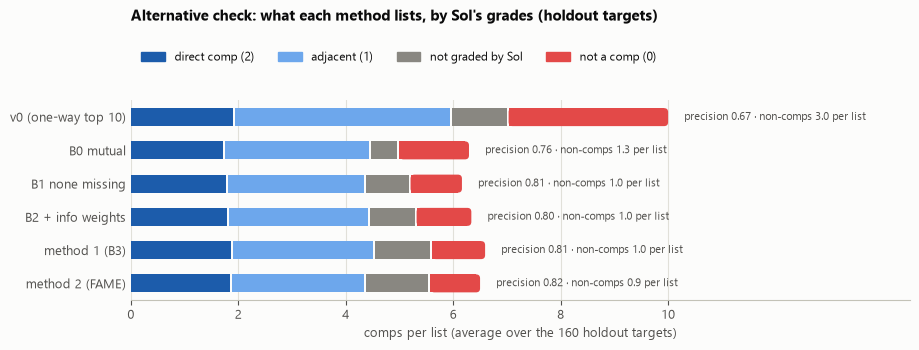

In [30]:
# the same picture as the golden-set chart, averaged over the 160 holdout targets, with Sol's grades
sol_map = dict(zip(zip(sol["target"], sol["comp"]), sol["grade"]))
SOL_KINDS = [("2", "direct comp (2)", DIRECT), ("1", "adjacent (1)", ADJACENT), ("?", "not graded by Sol", NEUTRAL),
             ("0", "not a comp (0)", NONCOMP)]
fig, ax = plt.subplots(figsize=(9.5, 3.5))
fig.subplots_adjust(left=0.16, right=0.98, top=0.72, bottom=0.15)
ax.set_xlim(0, 14.5)
ax.set_ylim(len(METHODS) - 0.5, -0.5)
for k, name in enumerate(METHODS):
    d = sel_hold[name]
    g = pd.Series([sol_map.get((a, b)) for a, b in zip(d["target"], d["comp"])], dtype="float")
    per = {"2": (g == 2).sum(), "1": (g == 1).sum(), "?": g.isna().sum(), "0": (g == 0).sum()}
    per = {key: v / len(holdout) for key, v in per.items()}
    stacked_hbar(ax, k, [(per[code], color) for code, _, color in SOL_KINDS])
    ax.text(sum(per.values()) + 0.3, k, f"precision {sol_metrics.loc[name, 'precision@10']:.2f} · non-comps {per['0']:.1f} per list",
            va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(METHODS)), [SHORT[m].replace("\n", " ") for m in METHODS])
ax.set_xticks(range(0, 11, 2))
ax.set_xlabel("comps per list (average over the 160 holdout targets)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Patch(color=c, label=l) for _, l, c in SOL_KINDS], loc="upper left", bbox_to_anchor=(0.16, 0.89),
           ncol=4, frameon=False, fontsize=8.5)
fig.suptitle("Alternative check: what each method lists, by Sol's grades (holdout targets)", x=0.16, ha="left",
             y=0.98, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "sol_hits_by_method.png", dpi=150)
plt.show()

**Reading (alternative evaluation, not used for decisions).**
- **Coverage and consistency.** 2,840 graded pairs on 156 holdout targets. The two Sol runs agree exactly on 91% of the 1,457 pairs both graded.
- **Precision.** On graded comps, precision@10 rises from 0.67 (v0) to 0.76 with the mutual filter alone, and to 0.81–0.82 with "none" as missing (B1, B3, M2). The share of direct comps goes from 0.21 to 0.32. This agrees in direction with the reviewers.
- **Labeled share** falls from 0.92 to 0.82–0.84, because the new lists include comps Sol never graded.
- **NDCG** is lower for the mutual lists (0.67–0.70 against 0.79). NDCG compares a list with the best order of *all* of a target's graded pairs, so a list of 6–7 comps can't reach an ideal of 10. Precision is the fairer comparison across list lengths.

## 6. Valuation: estimate from the comps' EV/EBITDA

**EV/EBITDA is read here for the first time**, after every comp list above is fixed. As in v0, each target's estimate is the similarity-weighted mean of its comps' multiples, and the comps come from the other training firms. APE is the absolute percentage error, |estimate − actual| / actual. The table gives the median over the 373 training targets, with 95% bootstrap intervals that resample targets:
- **gain on no matching:** the pool median's APE minus the method's.
- **gain on B0 one-way:** v0's cosine top-10 rule's APE minus the method's.

Both gains are paired, so positive means better and an interval that includes 0 means no shown difference.

**Reference rows.** Two of v0's LLM routes come from their saved Haiku outputs, with no new calls: cosine → LLM (`cosine_then_llm.py`'s verdicts on B0's z ≥ 2 shortlist) and direct LLM (`direct_llm.py`'s picks). They cover the targets those runs completed. They show where the LLM routes stood; they were not re-run on the new lists.

In [31]:
import cosine_then_llm as ctl
import direct_llm as dl

financials = pd.read_csv(UNIVERSE_RUN / "financials.csv", dtype={"IQ_COMPANY_ID": str}).set_index("IQ_COMPANY_ID")
ev = financials["target_ev_to_ebitda"]          # the answer key: first read here
actual = ev[training]
NO_MATCH = "no matching (pool median)"
results ={NO_MATCH: vl.no_matching(training, training, ev)}
for name, sel in {**sel_train, **diag_train}.items():
    results[name] = vl.estimate(sel, ev, weight="similarity")

# reference: v0's saved LLM routes (as in comps_and_valuation.ipynb, section 7)
judgments = pd.read_csv(ctl.output_paths(V1 / "judge").tables / "judgments.csv", dtype={"target": str, "comp": str})
judgments = judgments[judgments["prompt_version"] == ctl.SAVED_PROMPT_VERSION]
z2 = b0_rank[b0_rank[f"z_ge_{ctl.DEFAULT_Z:g}"]][["target", "comp", "rank", "similarity"]]
judged = z2.merge(judgments[["target", "comp", "score"]], on=["target", "comp"], how="left")
complete = judged.groupby("target")["score"].apply(lambda s: s.notna().all())
judged = judged[judged["target"].isin(complete[complete].index)]
results["ref: v0 cosine → LLM (saved Haiku verdicts)"] = vl.estimate(judged[judged["score"] == 1], ev, weight="similarity")
suggestions = pd.read_csv(dl.output_paths(V1 / "suggest").tables / "suggestions.csv", dtype={"target": str, "comp": str})
suggestions = suggestions[(suggestions["prompt_version"] == dl.SAVED_PROMPT_VERSION) & suggestions["target"].isin(training)
                          & (suggestions["comp"].isna() | suggestions["comp"].isin(training))]
results["ref: v0 direct LLM (saved Haiku picks)"] = vl.estimate(suggestions.dropna(subset=["comp"]), ev)

summary = vl.summary(results, actual, baseline=NO_MATCH)
boot_nm = vl.bootstrap(results, actual, baseline=NO_MATCH)
boot_b0 = vl.bootstrap(results, actual, baseline=B0_RULE)
nm = boot_nm.rename(columns={"error 2.5%": "APE 2.5%", "error 97.5%": "APE 97.5%", "gain on baseline": "gain on no matching",
                             "gain 2.5%": "no matching 2.5%", "gain 97.5%": "no matching 97.5%"})
b0 = boot_b0.rename(columns={"gain on baseline": "gain on B0 one-way", "gain 2.5%": "B0 2.5%", "gain 97.5%": "B0 97.5%"})
valuation = (summary[["targets", "comps per target (median)", "median abs % error", "% within 25%"]]
             .join(nm[["APE 2.5%", "APE 97.5%", "gain on no matching", "no matching 2.5%", "no matching 97.5%"]])
             .join(b0[["gain on B0 one-way", "B0 2.5%", "B0 97.5%"]]))
valuation.round(2)

,targets,comps per target (median),median abs % error,% within 25%,APE 2.5%,APE 97.5%,gain on no matching,no matching 2.5%,no matching 97.5%,gain on B0 one-way,B0 2.5%,B0 97.5%
comp rule,,,,,,,,,,,,
no matching (pool median),373,372.0,31.92,38.87,29.39,34.43,NaN,NaN,NaN,-3.10,-5.45,1.50
B0 one-way (v0),373,10.0,28.82,42.90,26.28,33.98,3.10,-1.49,5.53,NaN,NaN,NaN
B0 mutual,373,6.0,30.18,40.48,26.85,33.75,1.75,-1.47,4.98,-1.36,-3.30,2.65
B1: none as missing,373,6.0,32.05,39.95,28.59,33.97,-0.13,-2.26,3.01,-3.23,-4.80,0.60
B2: + information weights,373,6.0,32.35,40.21,28.41,35.11,-0.42,-2.93,3.33,-3.52,-5.22,0.44
B3: + TF-IDF blend = method 1,373,7.0,29.99,42.36,26.49,34.13,1.94,-1.36,5.44,-1.17,-3.98,2.58
M2: gate + pieces = method 2,373,7.0,30.26,41.02,26.52,33.01,1.66,-0.75,5.39,-1.44,-3.08,2.69
"diagnostic: method 1, one-way top 10",373,10.0,29.70,41.29,26.29,34.82,2.22,-1.98,5.64,-0.88,-3.88,1.88
"diagnostic: method 2, one-way top 10",373,10.0,30.15,41.29,27.32,33.00,1.77,-0.76,4.88,-1.33,-3.21,2.17


**Reading.**
- **v0 is reproduced exactly:** no matching 31.92%, B0 one-way 28.82%.
- **No method beats v0's top 10.**
  - Method 1 is at 29.99% and method 2 at 30.26%: −1.2 and −1.4 points against B0 one-way, with intervals −4.0 to +2.6 and −3.1 to +2.7.
  - B1 and B2 are the weakest, at 32.1% and 32.4%.
  - The diagnostic rows use v0's one-way top 10 with the new similarities and give 29.70% and 30.15%, so the mutual filter's shorter lists are not the reason.
- **Against no matching,** no rule's interval excludes 0, v0's included (+3.1, −1.5 to +5.5). The saved LLM routes sit at 30.5–30.6%.
- **What this means.** Every rule is within noise of every other, between 28.8% and 32.4%. Choosing comps that are better business peers doesn't make the EV/EBITDA estimate more accurate here. Moving valuation error will take more than comp selection, for example what drives the multiple within a peer group.

## 7. Facet-label check: do the information weights favor facets the reviewers found wrong?

Yifan, Riya and Fiona checked 480 facet values (40 companies × 12 facets) against sources. F9 is left out here, and so are "can't tell" labels. "Same text" is the share of labeled values that still match the current facet table, since a label only applies to the text it checked.

In [32]:
fl = pd.read_csv(V1 / "gold_labels/source/facet_gold_labels - Labels.csv", dtype=str)
name_of = {v: k for k, v in fc.FACET_ID.items()}
fl = fl.assign(facet=fl["facet_id"].map(name_of), company=fl["ticker"].map(id_of), label=fl["label"].str.strip())
fl = fl[fl["facet"].isin(FACETS) & fl["company"].notna() & (fl["label"] != "can't tell")]
fl["correct"] = fl["label"].eq("correct")
fl["information"] = [info_score.at[c, f] if c in info_score.index else np.nan for c, f in zip(fl["company"], fl["facet"])]
fl["same text"] = [str(texts_v0.at[c, f]).strip() == str(v).strip() for c, f, v in zip(fl["company"], fl["facet"], fl["haiku_value"])]
check = fl.groupby("facet").agg(labels=("correct", "size"), pct_correct=("correct", "mean"),
                                info_correct=("information", lambda s: s[fl.loc[s.index, "correct"]].mean()),
                                info_not_correct=("information", lambda s: s[~fl.loc[s.index, "correct"]].mean()),
                                same_text=("same text", "mean"))
check["mean weight share %"] = weights_view["mean weight share %"].rename(index={v: k for k, v in label.items()})
check = check.rename(index=label).sort_values("pct_correct")
print(f"{len(fl)} labels; information when correct {fl.loc[fl['correct'], 'information'].mean():.3f}, "
      f"when not fully correct {fl.loc[~fl['correct'], 'information'].mean():.3f}")
check.round(3)

437 labels; information when correct 0.497, when not fully correct 0.507


,labels,pct_correct,info_correct,info_not_correct,same_text,mean weight share %
facet,,,,,,
F8 geography served,38,0.526,0.352,0.398,0.000,6.991
F1 offering description,40,0.550,0.696,0.715,0.000,13.198
F2 primary products,40,0.550,0.492,0.482,0.050,9.077
F3 primary services,40,0.625,0.449,0.450,0.025,7.864
F6 revenue model,40,0.650,0.568,0.552,0.075,10.431
F10 specialization,40,0.700,0.510,0.480,0.025,9.490
F4 customer segment,40,0.750,0.492,0.483,0.000,9.542
F11 distribution channels,40,0.750,0.537,0.555,0.000,9.987
F12 regulatory exposure,39,0.795,0.466,0.465,0.000,9.110


**Reading.**
- **No relationship either way.** Information is the same whether a facet value was labeled correct (0.497) or not fully correct (0.507), so the weights neither favor nor avoid facets the reviewers found wrong.
- **One tension.** Offering description gets the most weight (13.2%) but was fully correct only 55% of the time. Most of the rest were "partly correct", which is common for a three-sentence summary. Geography, the weakest at 53%, gets the second-lowest weight (7.0%).
- **Caveat.** The labels checked an earlier fill. Only 0–8% of labeled values match the current text word for word: the facts are the same but the wording differs. For example, PCTY F4 was labeled as "B2B: US mid-sized employers across many industries" and now reads "B2B: mid-sized private employers across many industries". Treat this check as indicative.

## 8. Sheet for the reviewers: new pairs the methods surfaced

For PCTY and WEN: every comp any method lists that is not among the 36 reviewed pairs. The sheet uses `golden_set.labeler_sheet`'s blind format: no rank, method, similarity or multiple, in shuffled order. Pairs are numbered `PCTY-T01`, … ("T" for top-up) so they can't be confused with the first sheet. Which method listed each pair is kept in a separate file.

In [33]:
reviewed = set(zip(reviewer_labels["target_id"], reviewer_labels["comp_id"]))
listed = pd.concat([sel.assign(method=name) for name, sel in sel_train.items()])
listed = listed[listed["target"].isin([id_of[t] for t in EXAMPLES])]
listed = listed[[(t, c) not in reviewed for t, c in zip(listed["target"], listed["comp"])]]
new_pool = (listed.groupby(["target", "comp"])["method"].agg(" | ".join).reset_index()
            .rename(columns={"target": "target_id", "comp": "comp_id", "method": "listed by"}))
b1 = facets[facets["business_id"] == "B1"].set_index("IQ_COMPANY_ID")
shown_all = pd.DataFrame({"ticker": ticker, "company": info["target_company_name"],
                          "sic_industry": info["target_primary_sic_industry"], "website": info["target_ciq_website"],
                          "offering": b1["offering_description"].reindex(info.index).fillna(""),
                          "customers": b1["customer_segment"].reindex(info.index).fillna("")})
sheet = gs.labeler_sheet(new_pool, {"target": shown_all, "comp": shown_all}, seed=2026)
sheet["pair"] = sheet["pair"].str.replace("-", "-T", n=1, regex=False)
TOPUP = OUT / "labels_topup"
TOPUP.mkdir(exist_ok=True)
sheet.to_csv(TOPUP / "topup_sheet.csv", index=False, encoding="utf-8-sig")
new_pool.assign(target=new_pool["target_id"].map(ticker), comp=new_pool["comp_id"].map(ticker)).to_csv(
    TOPUP / "methods_by_pair.csv", index=False)
print(f"{len(sheet)} new pairs ({sheet['target_ticker'].value_counts().to_dict()}) -> {TOPUP.relative_to(ROOT)}")

2 new pairs ({'WEN': 2}) -> outputs-local\v1\similarity_methods\20261104T075557Z\labels_topup


Only 2 pairs are new, both for WEN: HQI and PLNT. Every comp on PCTY's lists was already reviewed. The sheet is small enough to score at once. More targets, chosen where the methods disagree most, would add far more evidence than more pairs for these two.

## 9. Saved outputs

In [34]:
def ticked(d):
    return d.assign(target_ticker=d["target"].map(ticker), comp_ticker=d["comp"].map(ticker))

pd.concat([ticked(sel).assign(method=name, sample="training") for name, sel in sel_train.items()] +
          [ticked(sel).assign(method=name, sample="holdout") for name, sel in sel_hold.items()]).to_csv(OUT / "comp_lists.csv", index=False)
info_score.to_csv(OUT / "information.csv")
sharp.to_csv(OUT / "sharpness.csv")
gates.to_csv(OUT / "gates.csv")
diagnostics.to_csv(OUT / "diagnostics.csv")
weights_view.to_csv(OUT / "information_weights.csv")
reviewer_metrics.to_csv(OUT / "reviewer_metrics.csv", index=False)
strict.to_csv(OUT / "reviewer_strict_check.csv", index=False)
per_reviewer.to_csv(OUT / "reviewer_metrics_per_reviewer.csv", index=False)
pd.concat(rank_views, names=["target"]).to_csv(OUT / "reviewed_comp_ranks.csv")
facet_view.to_csv(OUT / "wen_reviewed_comps_by_facet.csv")
separation.to_csv(OUT / "m2_facet_separation.csv")
sol_metrics.to_csv(OUT / "sol_metrics.csv")
sol_stats.to_csv(OUT / "sol_runs.csv", index=False)
valuation.to_csv(OUT / "valuation.csv")
pd.concat({k: vl.errors(v, actual) for k, v in results.items()}, names=["method", "target"]).to_csv(OUT / "valuation_by_target.csv")
check.to_csv(OUT / "facet_label_check.csv")
# every method's full ranking for the ten showcase targets (the business-structure pilot targets), which the
# golden-set rounds (golden_set_showcase.ipynb) read for their rank charts
SHOWCASE = ["PCTY", "WEN", "CSL", "AFG", "BOC", "NWSA", "AZZ", "BBCP", "BUKS", "SNFC.A"]
pd.concat([cd.rank_candidates(Sm, ids, targets=[id_of[t] for t in SHOWCASE], pool=training)
           [["target", "rank", "comp", "similarity"]].assign(method=name) for name, Sm in S.items()]
          ).to_csv(OUT / "rankings_showcase.csv.gz", index=False)
(OUT / "run.json").write_text(json.dumps({
    "run": RUN, "universe_run": UNIVERSE_RUN.name, "split_run": SPLIT_RUN.name, "facets_version": fc.PROMPT_VERSION,
    "facets": FACETS, "excluded_facets": list(fw.EXCLUDED_FACETS), "none_as_missing": True,
    "embedding_model": cd.EMBED_MODEL, "v0_embedding_cache": cache_v0.name, "text_cache": TEXT_CACHE.name,
    "alpha": fw.ALPHA, "saturation_k": K_SAT, "top_k": fw.TOP_K, "min_comps": fw.MIN_COMPS,
    "reviewer_snapshot": {k: snapshot[k] for k in ("source", "sheet", "range", "fetched_at_utc")},
    "sol_runs": sol_stats["run"].tolist(), "judge_prompt_version": ctl.SAVED_PROMPT_VERSION,
    "direct_prompt_version": dl.SAVED_PROMPT_VERSION, "api_calls": 0,
}, indent=1), encoding="utf-8")
print("wrote", OUT.relative_to(ROOT))

wrote outputs-local\v1\similarity_methods\20261104T075557Z
